# Build Model Housing V5: investigación de outliers y preparación de datos por modelo

Notebook autocontenido: parte de `data/processed/ames_clean.csv` (salida de la EP1) y termina con un conjunto de datos listo para cada familia de modelos. Cada decisión de preparación se prueba y se justifica en este mismo notebook:

- Secciones 1 a 6: EDA, detección de outliers y efecto de cada tratamiento en Ridge y Lasso.
- Secciones 7 y 8: qué preparación necesitan Random Forest y XGBoost (escala, `log1p`, codificación).
- Secciones 9 a 11: alcance y limpieza. ¿Entrenar con las zonas no residenciales empeora las predicciones de las residenciales? ¿Conviene quitar las variables redundantes y casi constantes? ¿Qué hacer con las variables que solo se conocen después de la venta?
- Secciones 12 a 18: resumen de decisiones, pipelines finales y guardado de `df_ridge_lasso`, `df_random_forest` y `df_xgboost` en `data/processed/`.

La selección de hiperparámetros queda para el siguiente notebook.

Entorno: el notebook corre en Google Colab y en local (versiones mínimas en `requirements.txt`). Los números citados en el texto corresponden a la última ejecución en Colab. Con otras versiones de scikit-learn o XGBoost, los resultados de Random Forest y XGBoost cambian en algunos cientos de dólares de RMSE; por eso las decisiones de las secciones 9 a 11 quedan fijas en el código y no dependen de esas diferencias.

**Importación de librerías**

In [1]:
# Manipulación y visualización
import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (StandardScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, FunctionTransformer, TargetEncoder)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

# Modelos
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Validación
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
# Aviso informativo al transformar: las categorías no vistas en train ya se manejan
# (dummies en 0 o grupo "infrecuente"; ver secciones 7.3 y 16)
warnings.filterwarnings('ignore', message='Found unknown categories')

# Reproducibilidad
RANDOM_STATE = 42

**Ejecución en Colab o en local**

En Colab, la celda siguiente clona la rama `RAMA` del repositorio en `/content` y se ubica en `notebooks/`, para que las rutas `../data/` funcionen igual que en local. En local no clona nada. En los dos casos imprime las versiones de las librerías, para dejar registrado con qué entorno se generaron los resultados.

In [2]:
import os, sys, shutil, subprocess
import sklearn, xgboost

RAMA = 'Nicolas'   # rama que se clona en Colab; cambiar a 'main' cuando se fusione
REPO = 'https://github.com/javisagredo-dev/Housing_Prices_ML_P2.git'

if 'google.colab' in sys.modules:
    RAIZ = '/content/Housing_Prices_ML_P2'
    # /content es temporal: se clona de nuevo en cada ejecución para usar siempre la última versión de RAMA
    os.chdir('/content')
    shutil.rmtree(RAIZ, ignore_errors=True)
    subprocess.run(['git', 'clone', '--depth', '1', '-b', RAMA, REPO, RAIZ], check=True)
    os.chdir(f'{RAIZ}/notebooks')

print('Carpeta de trabajo:', os.getcwd())
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Carpeta de trabajo: /content/Housing_Prices_ML_P2/notebooks
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1


`TargetEncoder` se importa desde scikit-learn y no desde `category_encoders`: su `fit_transform` aplica *cross-fitting* interno (encoding out-of-fold), la mejora que quedó pendiente en la EP1, y funciona dentro de un `Pipeline` sin fuga de datos en la validación cruzada.

## 1. EDA simple (revisión de los datos heredados del archivo EP1)

In [3]:
# keep_default_na=False: pandas convierte por defecto el texto "None" en NaN, lo que
# deshace la imputación de la EP1 (Alley, Pool QC, Garage..., Bsmt... volverían a tener nulos).
# Solo las celdas vacías se leen como NaN.
# Sin index_col: con index_col=0 la primera columna (MS SubClass) se convertía en el índice
# y desaparecía como variable.
df_clean = pd.read_csv('../data/processed/ames_clean.csv',
                       keep_default_na=False, na_values=[''])

# Si el CSV se guardó con el índice, aparece como columna 'Unnamed: 0'
df_clean = df_clean.drop(columns=['Unnamed: 0'], errors='ignore')

In [4]:
print(f"Dimensiones: {df_clean.shape}")              # esperado: (2925, 80)
print(f"Nulos totales: {df_clean.isnull().sum().sum()}")  # esperado: 0
print(f"¿MS SubClass es columna?: {'MS SubClass' in df_clean.columns}")

Dimensiones: (2925, 80)
Nulos totales: 0
¿MS SubClass es columna?: True


In [5]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2925 entries, 0 to 2924
Data columns (total 80 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2925 non-null   int64  
 1   MS Zoning        2925 non-null   object 
 2   Lot Frontage     2925 non-null   float64
 3   Lot Area         2925 non-null   int64  
 4   Street           2925 non-null   object 
 5   Alley            2925 non-null   object 
 6   Lot Shape        2925 non-null   object 
 7   Land Contour     2925 non-null   object 
 8   Utilities        2925 non-null   object 
 9   Lot Config       2925 non-null   object 
 10  Land Slope       2925 non-null   object 
 11  Neighborhood     2925 non-null   object 
 12  Condition 1      2925 non-null   object 
 13  Condition 2      2925 non-null   object 
 14  Bldg Type        2925 non-null   object 
 15  House Style      2925 non-null   object 
 16  Overall Qual     2925 non-null   int64  
 17  Overall Cond  

## 2. Detección de outliers: IQR vs Z-score

In [6]:
# Variables continuas donde tiene sentido buscar outliers
cols_continuas = ['SalePrice', 'Lot Frontage', 'Lot Area', 'Mas Vnr Area',
                  'BsmtFin SF 1', 'Bsmt Unf SF', 'Total Bsmt SF', '2nd Flr SF',
                  'Gr Liv Area', 'Wood Deck SF', 'Open Porch SF']

In [7]:
def outliers_iqr(df, cols, k=1.5):
    resultados = {}
    for col in cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - k * iqr, q3 + k * iqr
        resultados[col] = (df[col] < lim_inf) | (df[col] > lim_sup)
    return pd.DataFrame(resultados)

In [8]:
def outliers_zscore(df, cols, umbral=3):
    resultados = {}
    for col in cols:
        z = (df[col] - df[col].mean()) / df[col].std()
        resultados[col] = z.abs() > umbral
    return pd.DataFrame(resultados)

In [9]:
mask_iqr = outliers_iqr(df_clean, cols_continuas)
mask_z = outliers_zscore(df_clean, cols_continuas)

comparacion = pd.DataFrame({
    'IQR (n)': mask_iqr.sum(),
    'IQR (%)': (mask_iqr.mean() * 100).round(2),
    'Z-score (n)': mask_z.sum(),
    'Z-score (%)': (mask_z.mean() * 100).round(2),
    'Ambos métodos': (mask_iqr & mask_z).sum(),
    'Asimetría (skew)': df_clean[cols_continuas].skew().round(2)
}).sort_values('IQR (n)', ascending=False)

print(comparacion.to_string())

# Casas marcadas como outlier en al menos una variable por ambos métodos
filas_ambos = (mask_iqr & mask_z).any(axis=1)
print(f"\nCasas outlier por ambos métodos en al menos una variable: {filas_ambos.sum()} "
      f"({filas_ambos.mean()*100:.1f}%)")

               IQR (n)  IQR (%)  Z-score (n)  Z-score (%)  Ambos métodos  Asimetría (skew)
Lot Frontage       202     6.91           28         0.96             28              1.09
Mas Vnr Area       200     6.84           63         2.15             63              2.58
Open Porch SF      156     5.33           50         1.71             50              2.50
SalePrice          135     4.62           46         1.57             46              1.59
Lot Area           125     4.27           26         0.89             26             13.20
Total Bsmt SF      120     4.10           18         0.62             18              0.40
Gr Liv Area         70     2.39           23         0.79             23              0.88
Wood Deck SF        66     2.26           41         1.40             41              1.85
Bsmt Unf SF         56     1.91           16         0.55             16              0.93
BsmtFin SF 1        11     0.38           15         0.51             11              0.82

El IQR marca bastantes más casos que el z-score. Antes de decidir qué hacer con ellos se revisa de qué tipo es cada outlier: un artefacto del método, una cola larga natural o un caso que el modelo predice mal (sección 5).

### 2.1 Variables con muchos ceros

Cuando una cuarta parte o más de las casas no tiene la característica (valor 0), Q1 queda en 0 y los límites del IQR mezclan dos grupos: las casas sin la característica y las que sí la tienen. Se compara el IQR sobre toda la variable con el IQR calculado solo sobre los valores distintos de cero.

In [10]:
def outliers_iqr_sin_ceros(serie, k=1.5):
    nz = serie[serie > 0]
    q1, q3 = nz.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((nz < q1 - k * iqr) | (nz > q3 + k * iqr)).sum()

ceros = pd.DataFrame({
    '% casas con 0': ((df_clean[cols_continuas] == 0).mean() * 100).round(1),
    'IQR (n) toda la variable': mask_iqr.sum(),
    'IQR (n) solo valores > 0': [outliers_iqr_sin_ceros(df_clean[c]) for c in cols_continuas]
}).sort_values('% casas con 0', ascending=False)

print(ceros.to_string())

               % casas con 0  IQR (n) toda la variable  IQR (n) solo valores > 0
Mas Vnr Area            60.5                       200                        63
2nd Flr SF              57.3                         6                        32
Wood Deck SF            52.2                        66                        68
Open Porch SF           44.4                       156                        86
BsmtFin SF 1            31.8                        11                        23
Bsmt Unf SF              8.4                        56                        58
Total Bsmt SF            2.7                       120                        40
Lot Area                 0.0                       125                       125
Lot Frontage             0.0                       202                       202
SalePrice                0.0                       135                       135
Gr Liv Area              0.0                        70                        70


En `Mas Vnr Area`, `2nd Flr SF`, `Wood Deck SF`, `Open Porch SF` y `BsmtFin SF 1`, entre el 32 % y el 61 % de las casas tiene 0. Al calcular el IQR solo sobre los valores distintos de cero, los outliers bajan mucho en `Mas Vnr Area` (de 200 a 63) y en `Open Porch SF` (de 156 a 86): en esas dos variables el IQR sobre toda la variable exagera, y los casos que marca son casas que tienen la característica, no errores. En `2nd Flr SF`, `Wood Deck SF` y `BsmtFin SF 1` el conteo no baja (en `2nd Flr SF` sube de 6 a 32), así que ahí los ceros no inflan el número de outliers.

### 2.2 Colas largas: ¿qué variables mejoran con `log1p`?

Para los modelos lineales, una cola larga hace que unos pocos valores extremos tiren del coeficiente. En lugar de eliminar filas, se evalúa si la transformación logarítmica corrige la asimetría. Se aplica solo donde reduce la asimetría al menos a la mitad sin que la correlación con el precio caiga más de 0,10 (criterio de la celda siguiente).

In [11]:
log_precio = np.log1p(df_clean['SalePrice'])
predictoras = [c for c in cols_continuas if c != 'SalePrice']   # el target se trata aparte

asimetria = pd.DataFrame({
    'Skew original': df_clean[predictoras].skew(),
    'Skew con log1p': np.log1p(df_clean[predictoras]).skew(),
    'Corr. con precio': df_clean[predictoras].corrwith(df_clean['SalePrice']),
    'Corr. log vs log precio': np.log1p(df_clean[predictoras]).corrwith(log_precio)
}).round(2)

# Criterio: el log debe reducir la asimetría al menos a la mitad
# y no debe hacer caer la correlación con el precio en más de 0,10
reduce_skew = asimetria['Skew con log1p'].abs() < 0.5 * asimetria['Skew original'].abs()
no_pierde_senal = (asimetria['Corr. log vs log precio'] - asimetria['Corr. con precio']) > -0.10
asimetria['¿Aplicar log?'] = np.where(reduce_skew & no_pierde_senal, 'Sí', 'No')

print(asimetria.sort_values('Skew original', ascending=False).to_string())

               Skew original  Skew con log1p  Corr. con precio  Corr. log vs log precio ¿Aplicar log?
Lot Area               13.20           -0.53              0.27                     0.37            Sí
Mas Vnr Area            2.58            0.54              0.51                     0.44            Sí
Open Porch SF           2.50           -0.04              0.32                     0.46            Sí
Wood Deck SF            1.85            0.16              0.33                     0.35            Sí
Lot Frontage            1.09           -1.07              0.36                     0.34            No
Bsmt Unf SF             0.93           -2.14              0.19                     0.19            No
Gr Liv Area             0.88           -0.06              0.72                     0.73            Sí
2nd Flr SF              0.85            0.31              0.26                     0.13            No
BsmtFin SF 1            0.82           -0.62              0.44                    

Se aplica `log1p` a `Lot Area` (asimetría de 13,2 a −0,5), `Mas Vnr Area`, `Open Porch SF`, `Wood Deck SF` y `Gr Liv Area`.

No se aplica al resto, que se mantiene con `RobustScaler`:

- `Total Bsmt SF` y `Bsmt Unf SF`: la asimetría empeora (−4,96 y −2,14), porque los ceros quedan muy separados del resto.
- `Lot Frontage`: queda igual de asimétrica, solo que hacia la izquierda (1,09 a −1,07).
- `2nd Flr SF`: la asimetría baja, pero la correlación con el precio cae a la mitad (0,26 a 0,13).
- `BsmtFin SF 1`: la asimetría casi no mejora (0,82 a −0,62) y la correlación con el precio cae de 0,44 a 0,24.

`SalePrice` no aparece en la tabla porque se trata aparte: los modelos se entrenan sobre `log1p(SalePrice)` (sección 4).

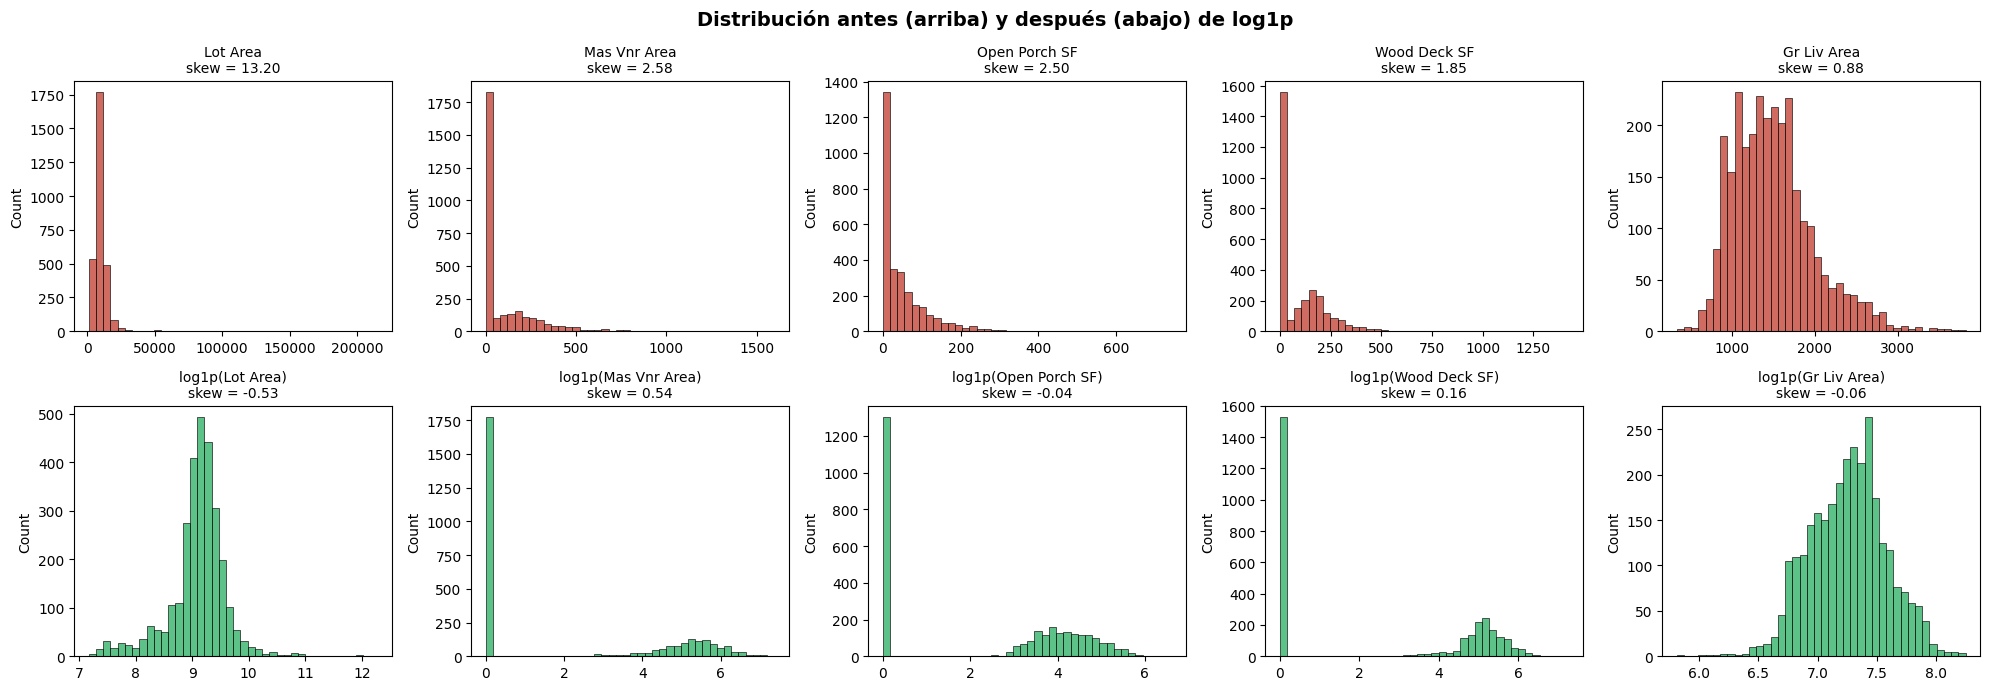

In [12]:
vars_log = ['Lot Area', 'Mas Vnr Area', 'Open Porch SF', 'Wood Deck SF', 'Gr Liv Area']

fig, axes = plt.subplots(2, len(vars_log), figsize=(20, 7))
for i, col in enumerate(vars_log):
    sns.histplot(df_clean[col], ax=axes[0, i], color='#c0392b', bins=40)
    axes[0, i].set_title(f'{col}\nskew = {df_clean[col].skew():.2f}', fontsize=10)
    sns.histplot(np.log1p(df_clean[col]), ax=axes[1, i], color='#27ae60', bins=40)
    axes[1, i].set_title(f'log1p({col})\nskew = {np.log1p(df_clean[col]).skew():.2f}', fontsize=10)
    axes[0, i].set_xlabel(''); axes[1, i].set_xlabel('')
plt.suptitle('Distribución antes (arriba) y después (abajo) de log1p', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3 Inspección de los casos extremos

Antes de decidir, se revisa si los valores extremos corresponden a errores de registro o a propiedades reales.

In [13]:
print("=== Lotes más grandes (Lot Area) ===")
print(df_clean.nlargest(6, 'Lot Area')[['Lot Area', 'Lot Frontage', 'Gr Liv Area', 'SalePrice',
                                        'Neighborhood', 'Land Contour', 'Sale Condition']].to_string())

print("\n=== Frentes de lote más largos (Lot Frontage) ===")
print(df_clean.nlargest(6, 'Lot Frontage')[['Lot Frontage', 'Lot Area', 'Gr Liv Area', 'SalePrice',
                                            'Neighborhood', 'Lot Config']].to_string())

print("\n=== Precios más bajos (SalePrice) ===")
print(df_clean.nsmallest(6, 'SalePrice')[['SalePrice', 'Gr Liv Area', 'Overall Qual', 'Functional',
                                          'MS Zoning', 'Sale Condition', 'Neighborhood']].to_string())

=== Lotes más grandes (Lot Area) ===
      Lot Area  Lot Frontage  Gr Liv Area  SalePrice Neighborhood Land Contour Sale Condition
956     215245         150.0         2036     375000       Timber          Low         Normal
1569    164660          82.0         1786     228950       Timber          HLS         Normal
2112    159000          80.5         2144     277000      ClearCr          Low         Normal
2068    115149          80.5         1824     302000      ClearCr          Low         Normal
2761     70761          62.0         1533     280000      ClearCr          Low         Normal
314      57200          82.0         1687     160000       Timber          Bnk         Normal

=== Frentes de lote más largos (Lot Frontage) ===
      Lot Frontage  Lot Area  Gr Liv Area  SalePrice Neighborhood Lot Config
1265         313.0     27650         2069     242000        NAmes     Inside
2273         200.0     43500         2034     130000      Mitchel     Inside
1637         195.0     

- Los lotes más grandes son ventas `Normal` en terrenos bajos o con pendiente (`Low`, `HLS`, `Bnk`): son propiedades reales, no errores. Se tratan con `log1p` y no se eliminan.
- De las 6 ventas más baratas, 5 son `Abnorml` y 3 están en zonas no residenciales (`A (agr)`, `C (all)`); una es una propiedad para demolición (`Functional = Sal`). Ese patrón se revisa a continuación.

In [14]:
zonas_no_residenciales = ['A (agr)', 'C (all)', 'I (all)']

zonificacion = df_clean.groupby('MS Zoning')['SalePrice'].agg(['size', 'median']).sort_values('median')
print("=== Precio por tipo de zonificación ===")
print(zonificacion.to_string())

no_res = df_clean[df_clean['MS Zoning'].isin(zonas_no_residenciales)]
print(f"\nPropiedades en zona no residencial: {len(no_res)}")
print("Barrio de esas propiedades:")
print(no_res['Neighborhood'].value_counts().to_string())

=== Precio por tipo de zonificación ===
           size    median
MS Zoning                
A (agr)       2   47300.0
C (all)      25   78000.0
I (all)       2   80312.5
RM          462  120750.0
RH           27  140000.0
RL         2268  171962.5
FV          139  209000.0

Propiedades en zona no residencial: 29
Barrio de esas propiedades:
Neighborhood
IDOTRR     25
OldTown     2
SWISU       1
Mitchel     1


Hay 29 propiedades en zona comercial, industrial o agrícola, con medianas de 47.300 a 80.313 USD, frente a 120.750 USD de `RM`, la zona residencial más barata. De ellas, 25 están en `IDOTRR`, el barrio con peor error en la auditoría de equidad de la EP1.

## 3. Encoding determinista (mismo criterio de la EP1)

Para evaluar los tratamientos con modelos lineales se necesitan las variables numéricas. Se repiten los pasos deterministas de la EP1 (no aprenden de los datos, así que pueden ir antes del split): `MS SubClass` a texto, mapeo ordinal manual y one-hot. El target encoding y el escalado van dentro del pipeline.

In [15]:
df_encoded = df_clean.copy()

# MS SubClass es un código de tipo de vivienda, no una cantidad
df_encoded['MS SubClass'] = df_encoded['MS SubClass'].astype(str)

# Encoding ordinal (mapeo manual)
map_calidad = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
cols_calidad = ['Exter Qual', 'Exter Cond', 'Bsmt Qual', 'Bsmt Cond', 'Heating QC',
                'Kitchen Qual', 'Fireplace Qu', 'Garage Qual', 'Garage Cond', 'Pool QC']
for col in cols_calidad:
    df_encoded[col] = df_encoded[col].map(map_calidad)

mapeos = {
    'Bsmt Exposure':  {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFin Type 1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFin Type 2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'Garage Finish':  {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional':     {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'Fence':          {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'Paved Drive':    {'N': 0, 'P': 1, 'Y': 2},
    'Lot Shape':      {'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3},
    'Land Slope':     {'Sev': 0, 'Mod': 1, 'Gtl': 2},
    'Utilities':      {'ELO': 0, 'NoSeWa': 1, 'NoSewr': 2, 'AllPub': 3},
}
for col, mapa in mapeos.items():
    df_encoded[col] = df_encoded[col].map(mapa)

cols_ordinales = cols_calidad + list(mapeos.keys())
print(f"NaN tras el mapeo ordinal (debe ser 0): {df_encoded[cols_ordinales].isnull().sum().sum()}")

# One-hot de nominales de baja cardinalidad
nominales_baja_card = ['MS SubClass', 'MS Zoning', 'Street', 'Alley', 'Land Contour',
                       'Lot Config', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
                       'Mas Vnr Type', 'Foundation', 'Heating', 'Central Air', 'Electrical',
                       'Garage Type', 'Misc Feature', 'Sale Type', 'Sale Condition',
                       'Condition 1', 'Condition 2']
df_encoded = pd.get_dummies(df_encoded, columns=nominales_baja_card, drop_first=True, dtype=int)

y = df_encoded['SalePrice']
X = df_encoded.drop(columns=['SalePrice'])
print(f"X: {X.shape} | y: {y.shape}")

NaN tras el mapeo ordinal (debe ser 0): 0
X: (2925, 169) | y: (2925,)


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (2340, 169) | X_test: (585, 169)


## 4. Efecto de cada tratamiento en Ridge y Lasso (validación cruzada)

Se comparan cuatro variantes con validación cruzada de 5 folds, solo sobre train. El test no se toca. Todo el preprocesamiento que aprende de los datos (target encoding, escalado, recorte) va dentro del `Pipeline`, de modo que se ajusta de nuevo en cada fold. `TransformedTargetRegressor` entrena sobre `log1p(SalePrice)` y devuelve las predicciones en dólares.

| Variante | Tratamiento |
|---|---|
| A | Como en la EP1: `RobustScaler` + `StandardScaler` |
| B | A + `log1p` en las 5 variables con cola larga |
| C | B + recorte de `Lot Frontage` al percentil 99 |
| D | C + excluir propiedades en zona no residencial |

In [17]:
cols_target_enc = ['Neighborhood', 'Exterior 1st', 'Exterior 2nd']

cols_robust = ['Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'BsmtFin SF 1', 'Bsmt Unf SF',
               'Total Bsmt SF', '2nd Flr SF', 'Gr Liv Area', 'Wood Deck SF', 'Open Porch SF']

cols_standard = ['Year Built', 'Year Remod/Add', 'Overall Qual', 'Overall Cond',
                 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath',
                 'Bedroom AbvGr', 'Kitchen AbvGr', 'Fireplaces', 'Garage Cars',
                 'Mo Sold', 'Yr Sold', 'BsmtFin SF 2', 'Low Qual Fin SF', 'Enclosed Porch',
                 '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val']


class RecortePercentil(BaseEstimator, TransformerMixin):
    """Recorta cada columna en su percentil q, calculado solo con los datos de entrenamiento."""
    def __init__(self, q=0.99):
        self.q = q
    def fit(self, X, y=None):
        self.limite_ = np.quantile(np.asarray(X, dtype=float), self.q, axis=0)
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.limite_)


def construir_modelo(variante, regresor):
    if variante == 'A':
        transformadores = [('robust', RobustScaler(), cols_robust)]
    else:
        resto_robust = [c for c in cols_robust if c not in vars_log]
        rama_log = Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())])
        rama_robust = (Pipeline([('recorte', RecortePercentil(0.99)), ('scaler', RobustScaler())])
                       if variante in ('C', 'D') else RobustScaler())
        transformadores = [('log', rama_log, vars_log), ('robust', rama_robust, resto_robust)]

    transformadores += [
        ('standard', StandardScaler(), cols_standard),
        ('target', Pipeline([('te', TargetEncoder(target_type='continuous', random_state=RANDOM_STATE)),
                             ('scaler', StandardScaler())]), cols_target_enc),
    ]
    preprocesador = ColumnTransformer(transformadores, remainder='passthrough')
    return TransformedTargetRegressor(
        regressor=Pipeline([('pre', preprocesador), ('modelo', regresor)]),
        func=np.log1p, inverse_func=np.expm1)

In [18]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error',
            'mape': 'neg_mean_absolute_percentage_error', 'r2': 'r2'}

es_residencial = ~df_clean.loc[X_train.index, 'MS Zoning'].isin(zonas_no_residenciales)

regresores = {
    'Ridge': RidgeCV(alphas=np.logspace(-2, 3, 30)),
    'Lasso': LassoCV(alphas=np.logspace(-5, -1, 30), max_iter=50000, random_state=RANDOM_STATE),
}

filas = []
for nombre, regresor in regresores.items():
    for variante in ['A', 'B', 'C', 'D']:
        X_v, y_v = (X_train[es_residencial], y_train[es_residencial]) if variante == 'D' else (X_train, y_train)
        res = cross_validate(construir_modelo(variante, regresor), X_v, y_v,
                             cv=cv, scoring=metricas, return_train_score=True)
        filas.append({
            'Modelo': nombre, 'Variante': variante, 'n': len(y_v),
            'RMSE': -res['test_rmse'].mean(),
            'Desv. RMSE entre folds': res['test_rmse'].std(),
            'MAE': -res['test_mae'].mean(),
            'MAPE %': -res['test_mape'].mean() * 100,
            'R² (val)': res['test_r2'].mean(),
            'R² (train)': res['train_r2'].mean(),
        })

resultados_outliers = pd.DataFrame(filas)
print(resultados_outliers.round(3).to_string(index=False))

Modelo Variante    n      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)  R² (train)
 Ridge        A 2340 20438.843                1866.384 14044.156   8.542     0.929       0.940
 Ridge        B 2340 20334.964                1780.321 13949.853   8.430     0.930       0.939
 Ridge        C 2340 20598.640                1759.474 14028.192   8.452     0.928       0.938
 Ridge        D 2314 20503.814                1058.003 13842.291   8.085     0.928       0.938
 Lasso        A 2340 20545.911                1655.201 14139.810   8.592     0.929       0.937
 Lasso        B 2340 20625.243                1687.141 14111.175   8.503     0.928       0.936
 Lasso        C 2340 20907.225                1668.130 14213.309   8.535     0.926       0.934
 Lasso        D 2314 20687.004                1185.798 13946.129   8.123     0.926       0.936


- B (`log1p`) baja el MAPE de Ridge y Lasso en unos 0,1 puntos y el RMSE de Ridge en unos 100 USD; en Lasso el RMSE sube unos 80 USD. Las diferencias son menores que la variación entre folds. Se adopta B porque corrige la asimetría (sección 2.2) sin empeorar el modelo de forma clara.
- C (recorte de `Lot Frontage`) sube el RMSE de los dos modelos en unos 270 USD respecto de B: se descarta.
- D (excluir zonas no residenciales) baja el MAPE de 8,5 a 8,1 % en los dos modelos respecto de C, y la desviación del RMSE entre folds cae entre un 30 % y un 40 %. Parte de la mejora viene de quitar casos difíciles que además dejan de evaluarse, así que D no se puede comparar con las otras variantes como si fuera la misma población.

### 4.1 ¿Escalar también las columnas ordinales?

En las variantes A a D las columnas ordinales (calidades de 0 a 5, `Functional` de 0 a 7, etc.) y las binarias pasan sin escalar (`remainder='passthrough'`). Ridge y Lasso penalizan todos los coeficientes por igual, así que una variable en escala de 0 a 7 queda penalizada distinto que una estandarizada. Se compara la variante B con una variante E = B + `StandardScaler` en las ordinales.

In [19]:
def construir_modelo_e(regresor):
    # Variante B + StandardScaler en las ordinales
    resto_robust = [c for c in cols_robust if c not in vars_log]
    preprocesador = ColumnTransformer([
        ('log', Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())]), vars_log),
        ('robust', RobustScaler(), resto_robust),
        ('standard', StandardScaler(), cols_standard + cols_ordinales),
        ('target', Pipeline([('te', TargetEncoder(target_type='continuous', random_state=RANDOM_STATE)),
                             ('scaler', StandardScaler())]), cols_target_enc),
    ], remainder='passthrough')
    return TransformedTargetRegressor(
        regressor=Pipeline([('pre', preprocesador), ('modelo', regresor)]),
        func=np.log1p, inverse_func=np.expm1)


def resumir_cv(res, **etiquetas):
    # Promedia las métricas de cross_validate en una fila
    fila = dict(etiquetas)
    fila.update({'RMSE': -res['test_rmse'].mean(),
                 'Desv. RMSE entre folds': res['test_rmse'].std(),
                 'MAE': -res['test_mae'].mean(),
                 'MAPE %': -res['test_mape'].mean() * 100,
                 'R² (val)': res['test_r2'].mean()})
    if 'train_r2' in res:
        fila['R² (train)'] = res['train_r2'].mean()
    return fila


filas = []
for nombre, regresor in regresores.items():
    for variante, modelo in [('B', construir_modelo('B', regresor)), ('E', construir_modelo_e(regresor))]:
        res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas, return_train_score=True)
        filas.append(resumir_cv(res, Modelo=nombre, Variante=variante))

print(pd.DataFrame(filas).round(3).to_string(index=False))

Modelo Variante      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)  R² (train)
 Ridge        B 20334.964                1780.321 13949.853   8.430     0.930       0.939
 Ridge        E 20352.351                1795.359 13951.673   8.430     0.930       0.939
 Lasso        B 20625.243                1687.141 14111.175   8.503     0.928       0.936
 Lasso        E 20629.986                1701.002 14112.839   8.501     0.928       0.936


- E rinde igual que B (menos de 20 USD de diferencia en RMSE, muy por debajo de la desviación entre folds): con los `alpha` que eligen `RidgeCV` y `LassoCV` la penalización es pequeña y la escala de las ordinales casi no influye.
- Aun así se adopta E para el conjunto final: rinde igual, deja todas las variables en la misma escala frente a la penalización (importa más cuando la búsqueda de hiperparámetros pruebe `alpha` grandes) y hace comparables los coeficientes.

## 5. ¿Qué casas predice peor el modelo?

Para un modelo, los outliers que importan no son necesariamente los valores extremos de X, sino las casas que predice mal. Se obtienen predicciones fuera de muestra con `cross_val_predict` (variante B, Ridge) y se revisa dónde se concentra el error.

In [20]:
pred_cv = cross_val_predict(construir_modelo('B', RidgeCV(alphas=np.logspace(-2, 3, 30))),
                            X_train, y_train, cv=cv)

residuos = pd.DataFrame({'Real': y_train, 'Predicho': pred_cv.round(0)})
residuos['Error %'] = (np.abs(residuos['Real'] - residuos['Predicho']) / residuos['Real'] * 100).round(1)
residuos = residuos.join(df_clean[['MS Zoning', 'Sale Condition', 'Neighborhood',
                                   'Overall Qual', 'Gr Liv Area', 'Functional']])

print("=== Las 15 casas con mayor error porcentual ===")
print(residuos.sort_values('Error %', ascending=False).head(15).to_string())

=== Las 15 casas con mayor error porcentual ===
        Real  Predicho  Error % MS Zoning Sale Condition Neighborhood  Overall Qual  Gr Liv Area Functional
181    12789   62554.0    389.1        RM        Abnorml      OldTown             2          832        Typ
1552   13100   42406.0    223.7   A (agr)        Abnorml       IDOTRR             1          733        Sal
372    82500  187846.0    127.7        RL         Family       NWAmes             7         1411        Typ
1554   40000   84493.0    111.2   C (all)         Normal       IDOTRR             4         1317        Typ
1182  150000  301392.0    100.9        RL         Family      Veenker             9         2944        Typ
726    34900   66651.0     91.0   C (all)        Abnorml       IDOTRR             4          720        Typ
125    84900  161576.0     90.3        RL        Abnorml        NAmes             5         1728        Typ
561    62383  116644.0     87.0        RL         Normal       Sawyer             5     

In [21]:
print("=== MAPE por condición de venta ===")
print(residuos.groupby('Sale Condition')['Error %'].agg(n='size', MAPE='mean')
      .sort_values('MAPE').round(1).to_string())

print("\n=== MAPE según zonificación ===")
print(residuos.groupby(residuos['MS Zoning'].isin(zonas_no_residenciales)
                       .map({False: 'Residencial', True: 'No residencial'}))['Error %']
      .agg(n='size', MAPE='mean').round(1).to_string())

=== MAPE por condición de venta ===
                   n  MAPE
Sale Condition            
Normal          1927   7.2
Partial          187   8.9
AdjLand           10  13.3
Family            41  16.5
Alloca            20  17.2
Abnorml          155  19.1

=== MAPE según zonificación ===
                   n  MAPE
MS Zoning                 
No residencial    26  33.6
Residencial     2314   8.1


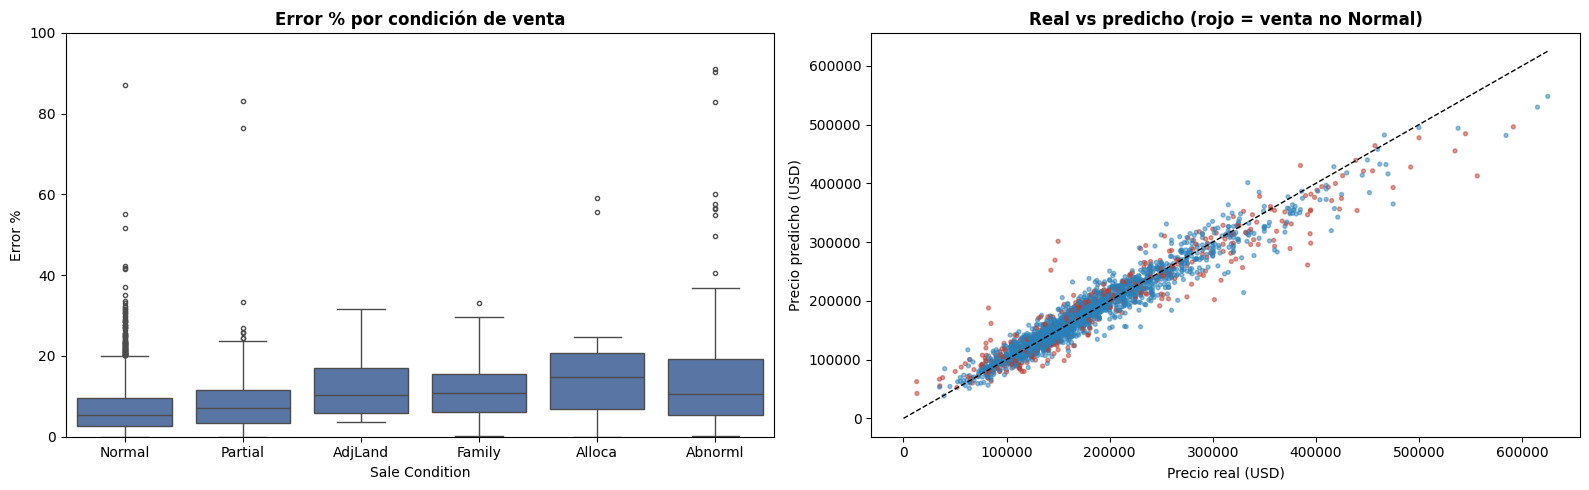

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

orden = residuos.groupby('Sale Condition')['Error %'].mean().sort_values().index
sns.boxplot(data=residuos, x='Sale Condition', y='Error %', order=orden, ax=axes[0],
            color='#4C72B0', fliersize=3)
axes[0].set_ylim(0, 100)
axes[0].set_title('Error % por condición de venta', fontweight='bold')

axes[1].scatter(residuos['Real'], residuos['Predicho'], s=8, alpha=0.5,
                c=residuos['Sale Condition'].eq('Normal').map({True: '#2980b9', False: '#c0392b'}))
lim = [0, residuos[['Real', 'Predicho']].max().max()]
axes[1].plot(lim, lim, 'k--', lw=1)
axes[1].set_xlabel('Precio real (USD)'); axes[1].set_ylabel('Precio predicho (USD)')
axes[1].set_title('Real vs predicho (rojo = venta no Normal)', fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Conclusiones y decisiones sobre outliers para Ridge y Lasso

1. No se eliminan filas por IQR ni por z-score. El 7,9 % que marcan ambos métodos son propiedades reales, y en `Mas Vnr Area` y `Open Porch SF` el IQR exagera por la gran cantidad de ceros.
2. `log1p` dentro del pipeline para `Lot Area`, `Gr Liv Area`, `Mas Vnr Area`, `Wood Deck SF` y `Open Porch SF`. El resto de las superficies se mantiene con `RobustScaler`.
3. `Lot Frontage` se mantiene sin recorte: recortarla empeoró el modelo.
4. Columnas ordinales escaladas con `StandardScaler` (variante E, sección 4.1): mismo rendimiento que B, con todas las variables en la misma escala frente a la penalización.
5. Zonas no residenciales (29 propiedades): todavía no se decide. Que el MAPE baje al sacarlas (variante D) es esperable, porque son las casas más difíciles y además dejan de evaluarse. Lo que hay que responder es si entrenar con ellas empeora las predicciones de las casas residenciales, y eso se prueba en la sección 9.
6. Las ventas `Abnorml`, `Alloca` y `Family` se conservan y se reportan como limitación: tienen el mayor error (MAPE de 19,1 %, 17,2 % y 16,5 %, frente a 7,2 % en las ventas `Normal`). No se pueden derivar a tasación manual, porque la condición de venta no se conoce antes de vender; el modelo estima el valor en una venta normal. El tratamiento de las variables de la venta se decide en la sección 11.
7. Random Forest y XGBoost se analizan en la sección 8; las variables redundantes y casi constantes, en la sección 10.

## 7. Preparación común: poblaciones, split y transformadores

### 7.1 Poblaciones y split

Se reutiliza el mismo split de la sección 3 (mismas casas en test). El EDA descriptivo de las secciones 2 y 10.1 (IQR, asimetría, variables casi constantes) se calculó sobre todo el dataset, test incluido; todas las comparaciones de modelos por validación cruzada usan solo train, y el test no participa en ningún ajuste. Se preparan dos versiones de train:

- `X_train_todo`: todas las casas. Las zonas `A (agr)`, `C (all)` e `I (all)` se agrupan en una sola categoría, `No residencial`: `A (agr)` e `I (all)` tienen 2 casas cada una y por separado el modelo no aprende nada de ellas.
- `X_train_res`: solo residenciales. Es la población que se usa en la sección 8.

In [23]:
df_clean.index.name = 'id'   # se conserva para rastrear cada casa hasta ames_clean.csv

df_todo = df_clean.copy()
df_todo['MS Zoning'] = df_todo['MS Zoning'].replace({z: 'No residencial' for z in zonas_no_residenciales})
es_residencial_todo = ~df_clean['MS Zoning'].isin(zonas_no_residenciales)

X_todo = df_todo.drop(columns=['SalePrice'])
y_todo = df_todo['SalePrice']

# Mismas casas que en el split de la sección 3, sin codificar
X_train_todo, y_train_todo = X_todo.loc[X_train.index], y_todo.loc[X_train.index]
X_test_todo, y_test_todo = X_todo.loc[X_test.index], y_todo.loc[X_test.index]
res_train = es_residencial_todo.loc[X_train.index]
res_test = es_residencial_todo.loc[X_test.index]

X_train_res, y_train_res = X_train_todo[res_train], y_train_todo[res_train]

print(f"Train todas: {X_train_todo.shape} ({(~res_train).sum()} no residenciales) | "
      f"Test todas: {X_test_todo.shape} ({(~res_test).sum()} no residenciales)")
print(f"Train solo residenciales: {X_train_res.shape}")
print(X_train_todo['MS Zoning'].value_counts().to_string())

Train todas: (2340, 79) (26 no residenciales) | Test todas: (585, 79) (3 no residenciales)
Train solo residenciales: (2314, 79)
MS Zoning
RL                1809
RM                 373
FV                 107
No residencial      26
RH                  25


### 7.2 Grupos de columnas

Se reutilizan las listas de la sección 3 y se completan los grupos que faltan. El control final asegura que cada
predictor está asignado a exactamente un grupo. `COLS_LIMPIEZA` son las columnas que se evalúan quitar en la
sección 10.

In [24]:
# Mapeo ordinal completo (calidades + resto de ordinales de la sección 3)
mapeos_ordinales = {**{col: map_calidad for col in cols_calidad}, **mapeos}

cols_robust_sin_log = [c for c in cols_robust if c not in vars_log]
cols_binarias = ['Tiene_Piscina', 'Tiene_Sotano', 'Tiene_Garage', 'Tiene_Chimenea']
cols_nominales = nominales_baja_card + cols_target_enc
cols_numericas = vars_log + cols_robust_sin_log + cols_standard

grupos = cols_ordinales + cols_nominales + cols_numericas + cols_binarias
assert len(grupos) == len(set(grupos)), "Hay columnas repetidas entre grupos"
assert set(grupos) == set(X_todo.columns), set(X_todo.columns) ^ set(grupos)
print(f"Predictores: {len(grupos)} = {len(cols_ordinales)} ordinales + {len(cols_nominales)} nominales "
      f"({len(nominales_baja_card)} de baja cardinalidad, {len(cols_target_enc)} de alta) "
      f"+ {len(cols_numericas)} numéricas + {len(cols_binarias)} binarias")

COLS_LIMPIEZA = ['Utilities', 'Street', 'Pool QC', 'Pool Area', 'BsmtFin SF 2']
MIN_FRECUENCIA = 10   # categorías con menos casas en train se agrupan en "infrecuente"


def filtrar(cols, limpieza, quitar=()):
    # Quita las columnas de COLS_LIMPIEZA cuando se aplica la limpieza, y las de 'quitar' siempre
    return [c for c in cols if not (limpieza and c in COLS_LIMPIEZA) and c not in quitar]

Predictores: 79 = 20 ordinales + 24 nominales (21 de baja cardinalidad, 3 de alta) + 31 numéricas + 4 binarias


### 7.3 Transformadores y preprocesadores

- `MapeoOrdinal`: los pasos deterministas de la sección 3 (`MS SubClass` a texto y mapeo ordinal manual), pero
  dentro del pipeline, para aplicar exactamente la misma preparación a casas nuevas.
- `ACategoria`: para la codificación nativa de XGBoost (comparada en la sección 8). Aprende las categorías en train
  y convierte las nominales a tipo `category`; una categoría que aparezca solo en test queda como `NaN`.
- `construir_pre_lineal` y `construir_pre_arbol`: preprocesadores de Ridge/Lasso y de los árboles. El parámetro
  `limpieza` activa el paquete de la sección 10 (quitar `COLS_LIMPIEZA` y agrupar categorías raras) y `quitar`
  permite sacar columnas adicionales (sección 11).

In [25]:
class MapeoOrdinal(BaseEstimator, TransformerMixin):
    # Pasos deterministas: MS SubClass como código (texto) y mapeo manual de las ordinales.
    def __init__(self, mapeos):
        self.mapeos = mapeos
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_
    def transform(self, X):
        X = X.copy()
        X['MS SubClass'] = X['MS SubClass'].astype(str)
        for col, mapa in self.mapeos.items():
            X[col] = X[col].map(mapa)
        if X[list(self.mapeos)].isnull().any().any():
            raise ValueError("Hay valores ordinales que no están en los mapeos")
        return X


class ACategoria(BaseEstimator, TransformerMixin):
    # Convierte las columnas nominales a 'category' con las categorías vistas en train.
    def __init__(self, cols):
        self.cols = cols
    def fit(self, X, y=None):
        self.categorias_ = {c: sorted(X[c].astype(str).unique()) for c in self.cols}
        return self
    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            valores = X[c].astype(str)
            valores = valores.where(valores.isin(self.categorias_[c]))   # no vistas en train -> NaN
            X[c] = valores.astype(CategoricalDtype(self.categorias_[c]))
        return X


def codificador(tipo, min_frecuencia=None, drop=None):
    if tipo == 'ordinal':
        return OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                              min_frequency=min_frecuencia, dtype=int)
    if tipo == 'onehot':
        # Con min_frequency, una categoría no vista en train cae en el grupo "infrecuente"
        return OneHotEncoder(drop=drop, min_frequency=min_frecuencia, sparse_output=False, dtype=int,
                             handle_unknown='infrequent_if_exist' if min_frecuencia else 'ignore')
    if tipo == 'target':
        return TargetEncoder(target_type='continuous', random_state=RANDOM_STATE)
    raise ValueError(tipo)


def construir_pre_lineal(limpieza=False, quitar=()):
    # Variante E de la sección 4.1: log1p + RobustScaler + StandardScaler (incluidas ordinales)
    min_frec = MIN_FRECUENCIA if limpieza else None
    columnas = ColumnTransformer([
        ('log', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('scaler', StandardScaler())]), vars_log),
        ('robust', RobustScaler(), cols_robust_sin_log),
        ('standard', StandardScaler(), filtrar(cols_standard + cols_ordinales, limpieza, quitar)),
        ('target', Pipeline([('te', codificador('target')), ('scaler', StandardScaler())]), cols_target_enc),
        ('onehot', codificador('onehot', min_frec, drop='first'), filtrar(nominales_baja_card, limpieza, quitar)),
        ('binarias', 'passthrough', cols_binarias),
    ], remainder='drop', verbose_feature_names_out=False)
    return Pipeline([('mapeo', MapeoOrdinal(mapeos_ordinales)), ('columnas', columnas)]).set_output(transform='pandas')


def construir_pre_arbol(baja, alta, limpieza=False, quitar=()):
    # baja / alta: codificación de las nominales de baja y alta cardinalidad
    min_frec = MIN_FRECUENCIA if limpieza else None
    columnas = ColumnTransformer([
        ('baja', codificador(baja, min_frec), filtrar(nominales_baja_card, limpieza, quitar)),
        ('alta', codificador(alta, min_frec), cols_target_enc),
        ('numericas', 'passthrough', filtrar(cols_numericas + cols_ordinales + cols_binarias, limpieza, quitar)),
    ], remainder='drop', verbose_feature_names_out=False)
    return Pipeline([('mapeo', MapeoOrdinal(mapeos_ordinales)), ('columnas', columnas)]).set_output(transform='pandas')


def construir_pre_xgb():
    return Pipeline([('mapeo', MapeoOrdinal(mapeos_ordinales)), ('categorias', ACategoria(cols_nominales))])


def con_log(regresor):
    return TransformedTargetRegressor(regressor=regresor, func=np.log1p, inverse_func=np.expm1)


def nuevo_rf():
    return RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)


def nuevo_xgb(**kw):
    return XGBRegressor(tree_method='hist', n_estimators=500, learning_rate=0.05,
                        random_state=RANDOM_STATE, **kw)

## 8. ¿Qué necesitan Random Forest y XGBoost?

Se comprueba con validación cruzada (mismos 5 folds, solo train residencial, preprocesamiento dentro del pipeline) en lugar de asumirlo. Hiperparámetros por defecto: el objetivo es decidir la preparación de datos, no ajustar los modelos.

### 8.1 ¿Les afecta el `log1p` o la escala de X?

Un árbol solo usa el orden de los valores para elegir sus cortes; cualquier transformación monótona (`log1p`, escalado) debería dar el mismo modelo. Se entrena cada modelo con y sin `log1p` en las 5 variables de cola larga.

In [26]:
X_train_log = X_train_res.copy()
X_train_log[vars_log] = np.log1p(X_train_log[vars_log])

pruebas_log = {
    'Random Forest': lambda: Pipeline([('pre', construir_pre_arbol('ordinal', 'target')), ('modelo', nuevo_rf())]),
    'XGBoost': lambda: Pipeline([('pre', construir_pre_xgb()), ('modelo', nuevo_xgb(enable_categorical=True))]),
}

filas = []
for nombre, modelo in pruebas_log.items():
    for etiqueta, X_v in [('Sin log1p', X_train_res), ('Con log1p', X_train_log)]:
        res = cross_validate(con_log(modelo()), X_v, y_train_res, cv=cv, scoring=metricas)
        filas.append(resumir_cv(res, Modelo=nombre, X=etiqueta))
print(pd.DataFrame(filas).round(3).to_string(index=False))

       Modelo         X      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
Random Forest Sin log1p 25126.341                2507.024 15797.569   9.231     0.892
Random Forest Con log1p 25122.631                2503.254 15792.326   9.233     0.892
      XGBoost Sin log1p 23084.991                1753.870 14495.938   8.467     0.909
      XGBoost Con log1p 23084.991                1753.870 14495.938   8.467     0.909


- Random Forest: unos 4 USD de diferencia en RMSE, ruido por la posición de los umbrales. XGBoost: resultados idénticos al dólar.
- Se confirma que los árboles no necesitan `log1p` ni escalado en X. Por la misma razón (solo importa el orden), los valores extremos de X no les afectan y no se recortan ni se eliminan.

### 8.2 Codificación de las nominales en Random Forest

Random Forest de scikit-learn necesita entrada numérica. Se comparan cuatro opciones:

| Opción | Baja cardinalidad (21) | Alta cardinalidad (`Neighborhood`, `Exterior 1st/2nd`) |
|---|---|---|
| 1 | Ordinal | Ordinal |
| 2 | One-hot | One-hot |
| 3 | One-hot | Target encoding |
| 4 | Ordinal | Target encoding |

In [27]:
opciones_rf = {1: ('ordinal', 'ordinal'), 2: ('onehot', 'onehot'),
               3: ('onehot', 'target'), 4: ('ordinal', 'target')}

filas = []
for opcion, (baja, alta) in opciones_rf.items():
    n_cols = construir_pre_arbol(baja, alta).fit_transform(X_train_res, np.log1p(y_train_res)).shape[1]
    modelo = con_log(Pipeline([('pre', construir_pre_arbol(baja, alta)), ('modelo', nuevo_rf())]))
    res = cross_validate(modelo, X_train_res, y_train_res, cv=cv, scoring=metricas)
    filas.append(resumir_cv(res, Opción=opcion, Baja=baja, Alta=alta, Columnas=n_cols))

print(pd.DataFrame(filas).round(3).to_string(index=False))

 Opción    Baja    Alta  Columnas      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
      1 ordinal ordinal        79 25179.413                2592.287 15886.571   9.288     0.891
      2  onehot  onehot       241 25085.989                2512.886 15830.380   9.254     0.892
      3  onehot  target       185 25137.568                2497.416 15799.360   9.218     0.891
      4 ordinal  target        79 25126.341                2507.024 15797.569   9.231     0.892


- Las cuatro opciones quedan a menos de 100 USD de RMSE entre sí, frente a una desviación entre folds de unos 2.500 USD: la codificación prácticamente no cambia el resultado de Random Forest.
- Ninguna opción gana en todas las métricas: la 2 (one-hot + one-hot) tiene el menor RMSE y la 3 (one-hot + target encoding) el menor MAPE, siempre por muy poco. Se adopta la 3, que usa la misma codificación elegida para XGBoost (sección 8.3) y 185 columnas en lugar de 241.
- Alternativa equivalente: la opción 4 (ordinal + target) rinde igual con 79 columnas y concentra la importancia de cada variable en una sola columna; puede preferirse si se prioriza la interpretación.

### 8.3 Codificación de las nominales en XGBoost

XGBoost puede usar las columnas `category` directamente (`enable_categorical=True`): en cada corte agrupa
categorías en dos lados en lugar de tratarlas como números. Se compara contra las dos codificaciones con
target encoding de la sección 8.2.

In [28]:
pruebas_xgb = {
    'Nativa (category)': Pipeline([('pre', construir_pre_xgb()),
                                   ('modelo', nuevo_xgb(enable_categorical=True))]),
    'Ordinal + target': Pipeline([('pre', construir_pre_arbol('ordinal', 'target')), ('modelo', nuevo_xgb())]),
    'One-hot + target': Pipeline([('pre', construir_pre_arbol('onehot', 'target')), ('modelo', nuevo_xgb())]),
}

filas = []
for nombre, modelo in pruebas_xgb.items():
    res = cross_validate(con_log(modelo), X_train_res, y_train_res, cv=cv, scoring=metricas)
    filas.append(resumir_cv(res, Codificación=nombre))
print(pd.DataFrame(filas).round(3).to_string(index=False))

     Codificación      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
Nativa (category) 23084.991                1753.870 14495.938   8.467     0.909
 Ordinal + target 22688.588                1430.975 14429.094   8.455     0.912
 One-hot + target 22411.845                1324.377 14378.209   8.446     0.914


- Con los hiperparámetros por defecto, la codificación nativa no es la mejor: one-hot + target baja el RMSE en unos 670 USD (2,9 %) y es más estable entre folds (desviación de 1.324 frente a 1.754). MAE y MAPE casi no cambian entre las tres opciones (menos de 120 USD y 0,03 puntos).
- Una explicación posible: con `Neighborhood` (28 categorías) como `category`, cada corte busca la mejor partición de los barrios, y con pocas casas por barrio eso tiende a sobreajustar; el target encoding resume el barrio en un único valor ordenado por precio.
- Se adopta one-hot + target para XGBoost. Como las diferencias son pequeñas, conviene volver a comparar la opción nativa durante la búsqueda de hiperparámetros (sección 18).

## 9. Zonas no residenciales: ¿entrenar con ellas empeora las residenciales?

Comparar el MAPE con y sin estas casas (variante D) no responde la pregunta, porque al sacarlas también se dejan de evaluar las casas más difíciles. Por eso la prueba es otra:

- En cada fold se entrenan dos modelos: uno con todas las casas del fold de entrenamiento y otro solo con las residenciales.
- Los dos se evalúan sobre las mismas casas residenciales del fold de validación.
- Se usan los cuatro modelos con la preparación elegida hasta aquí (Ridge y Lasso: variante E; árboles: one-hot + target encoding) y la zona agrupada como `No residencial`.

Criterio fijado antes de ver los resultados: las no residenciales empeoran a un modelo si el RMSE sobre residenciales sube en promedio y además en al menos 4 de los 5 folds. Se excluyen solo si eso ocurre en la mayoría de los modelos.

- Si no empeoran, se conservan con la zona agrupada, con métricas reportadas por separado para residenciales y no residenciales y con la recomendación de tasarlas manualmente (la zonificación sí se conoce antes de tasar).
- Si empeoran, se excluyen y se documenta.

La decisión que sale de esta prueba queda fija en el código (`EXCLUIR_NO_RESIDENCIAL`), igual que las de las secciones 10.2 y 11. La prueba se recalcula en cada ejecución y muestra un aviso si en otro entorno da un resultado distinto; así, una diferencia de pocos dólares entre versiones de librerías no cambia la preparación sin que nadie lo note.

In [29]:
modelos_finales = {
    'Ridge': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_lineal(limpieza, quitar)),
                                                      ('modelo', RidgeCV(alphas=np.logspace(-2, 3, 30)))])),
    'Lasso': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_lineal(limpieza, quitar)),
                                                      ('modelo', LassoCV(alphas=np.logspace(-5, -1, 30), max_iter=50000,
                                                                         random_state=RANDOM_STATE))])),
    'Random Forest': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_arbol('onehot', 'target', limpieza, quitar)),
                                                              ('modelo', nuevo_rf())])),
    'XGBoost': lambda limpieza=False, quitar=(): con_log(Pipeline([('pre', construir_pre_arbol('onehot', 'target', limpieza, quitar)),
                                                        ('modelo', nuevo_xgb())])),
}


def metricas_dolares(real, pred):
    return {'RMSE': root_mean_squared_error(real, pred), 'MAE': mean_absolute_error(real, pred),
            'MAPE %': mean_absolute_percentage_error(real, pred) * 100}


def revisar_decision(nombre, segun_prueba, decision):
    # Las decisiones de las secciones 9 a 11 están fijas en el código. La prueba se recalcula igual y, si en
    # otro entorno (otras versiones de librerías) da otro resultado, se avisa en vez de cambiar la preparación.
    print(f"{nombre}: según la prueba = {segun_prueba} | decisión fija = {decision}")
    if segun_prueba != decision:
        print(f"  Aviso: en este entorno la prueba no coincide con la decisión fija de {nombre}; revisar la tabla.")


predicciones = []
for nombre, construir in modelos_finales.items():
    for fold, (tr, va) in enumerate(cv.split(X_train_todo)):
        ids_tr, ids_va = X_train_todo.index[tr], X_train_todo.index[va]
        entrenamientos = {'Con no residenciales': ids_tr,
                          'Solo residenciales': ids_tr[res_train.loc[ids_tr].values]}
        for entrenamiento, ids in entrenamientos.items():
            modelo = construir().fit(X_train_todo.loc[ids], y_train_todo.loc[ids])
            predicciones.append(pd.DataFrame({
                'Modelo': nombre, 'Entrenamiento': entrenamiento, 'Fold': fold,
                'Real': y_train_todo.loc[ids_va], 'Predicho': modelo.predict(X_train_todo.loc[ids_va]),
                'Residencial': res_train.loc[ids_va]}))

predicciones = pd.concat(predicciones)
print(f"Predicciones fuera de muestra: {len(predicciones)} "
      f"({len(modelos_finales)} modelos x 2 entrenamientos x {len(X_train_todo)} casas)")

Predicciones fuera de muestra: 18720 (4 modelos x 2 entrenamientos x 2340 casas)


In [30]:
# Evaluación solo sobre casas residenciales
pred_res = predicciones[predicciones['Residencial']]

rmse_fold = (pred_res.groupby(['Modelo', 'Entrenamiento', 'Fold'])[['Real', 'Predicho']]
             .apply(lambda g: root_mean_squared_error(g['Real'], g['Predicho']))
             .unstack('Entrenamiento'))
diferencia = rmse_fold['Con no residenciales'] - rmse_fold['Solo residenciales']

mape = (pred_res.groupby(['Modelo', 'Entrenamiento'])[['Real', 'Predicho']]
        .apply(lambda g: mean_absolute_percentage_error(g['Real'], g['Predicho']) * 100)
        .unstack('Entrenamiento'))

prueba_zonas = pd.DataFrame({
    'RMSE con no res.': rmse_fold['Con no residenciales'].groupby('Modelo').mean(),
    'RMSE solo res.': rmse_fold['Solo residenciales'].groupby('Modelo').mean(),
    'Diferencia RMSE (con − solo)': diferencia.groupby('Modelo').mean(),
    'Folds en que empeora (de 5)': (diferencia > 0).groupby('Modelo').sum(),
    'MAPE % con no res.': mape['Con no residenciales'],
    'MAPE % solo res.': mape['Solo residenciales'],
}).loc[list(modelos_finales)]
prueba_zonas['¿Empeora?'] = ((prueba_zonas['Diferencia RMSE (con − solo)'] > 0)
                             & (prueba_zonas['Folds en que empeora (de 5)'] >= 4))

print("=== Error sobre casas residenciales según con qué se entrenó ===")
print(prueba_zonas.round(2).to_string())

excluir_segun_prueba = bool(prueba_zonas['¿Empeora?'].sum() > len(prueba_zonas) / 2)
print(f"\nModelos que empeoran: {prueba_zonas['¿Empeora?'].sum()} de {len(prueba_zonas)}")

EXCLUIR_NO_RESIDENCIAL = True   # decisión fija, justificada en el texto bajo esta prueba
revisar_decision('EXCLUIR_NO_RESIDENCIAL', excluir_segun_prueba, EXCLUIR_NO_RESIDENCIAL)

=== Error sobre casas residenciales según con qué se entrenó ===
               RMSE con no res.  RMSE solo res.  Diferencia RMSE (con − solo)  Folds en que empeora (de 5)  MAPE % con no res.  MAPE % solo res.  ¿Empeora?
Modelo                                                                                                                                                     
Ridge                  20345.68        20275.03                         70.64                            4                8.18              8.11       True
Lasso                  20727.26        20540.02                        187.24                            4                8.25              8.20       True
Random Forest          24671.58        24758.40                        -86.82                            2                9.09              9.16      False
XGBoost                22317.90        22166.80                        151.10                            4                8.18              8.19       True

In [31]:
# Error sobre las propias casas no residenciales (26 casas de train, fuera de muestra)
pred_nores = predicciones[~predicciones['Residencial']]
error_nores = (pred_nores.groupby(['Modelo', 'Entrenamiento'])[['Real', 'Predicho']]
               .apply(lambda g: pd.Series(metricas_dolares(g['Real'], g['Predicho'])))
               .unstack('Entrenamiento').loc[list(modelos_finales)])

print(f"=== Error sobre casas no residenciales (n = {pred_nores.index.nunique()}) ===")
print(error_nores.round(1).to_string())

=== Error sobre casas no residenciales (n = 26) ===
                              RMSE                                     MAE                                  MAPE %                   
Entrenamiento Con no residenciales Solo residenciales Con no residenciales Solo residenciales Con no residenciales Solo residenciales
Modelo                                                                                                                               
Ridge                      22552.5            23791.4              18422.2            17896.2                 33.7               37.0
Lasso                      23614.3            23450.6              19000.8            17785.5                 34.3               36.5
Random Forest              25424.0            26352.1              19150.4            20567.6                 42.5               43.8
XGBoost                    23832.8            23421.3              18163.8            17119.4                 36.1               38.7


**Resultado: según el criterio fijado, las zonas no residenciales se excluyen.**

- Entrenar con ellas empeora las predicciones de las casas residenciales en 3 de los 4 modelos (Ridge, Lasso y XGBoost), en 4 de los 5 folds en cada caso. Random Forest es la excepción: mejora levemente, en 3 de los 5 folds.
- El daño es consistente pero pequeño: entre 70 y 190 USD de RMSE (0,3 % a 0,9 %), frente a una variación entre folds de 1.000 a 2.500 USD. En MAPE las diferencias son de menos de 0,1 puntos y en XGBoost incluso cambian de signo. No cambia qué modelo gana; lo que cambia es que las residenciales no ganan nada a cambio.
- Entrenar con las casas no residenciales tampoco las vuelve tasables: su MAPE queda entre 34 % y 44 % con cualquiera de los dos entrenamientos, de 4 a 5 veces el error de las residenciales. Con 26 casas en train, el modelo no tiene datos suficientes para aprender ese mercado.

Decisión: se excluyen, y se documenta como criterio de alcance: el modelo tasa viviendas en zonas residenciales. Una propiedad en zona comercial, industrial o agrícola queda fuera de alcance y va a tasación manual.

Por qué se excluyen las zonas no residenciales y se conservan las ventas `Abnorml`: la zonificación es un atributo de la propiedad que se conoce antes de tasar, así que sirve como criterio de alcance para una casa nueva. La condición de venta (`Abnorml`, `Family`) solo se conoce después de vender, así que no se puede usar para decidir de antemano qué casas entran.

Para el análisis de sesgos: la exclusión saca 25 de las 93 casas de `IDOTRR` (las de zona no residencial, con mediana de 75.000 USD frente a 117.450 USD de las residenciales del barrio). Las 68 casas residenciales de `IDOTRR` siguen en el modelo, y `segmentos.csv` (sección 17) permite reportar su error por separado.

## 10. Variables redundantes y casi constantes

### 10.1 Diagnóstico

Las redundancias se comprueban con los datos en lugar de asumirlas desde la descripción de las variables.

In [32]:
print("=== Identidades exactas (proporción de casas en que se cumplen) ===")
suma_sotano = df_clean['BsmtFin SF 1'] + df_clean['BsmtFin SF 2'] + df_clean['Bsmt Unf SF']
identidades = {
    'Total Bsmt SF = BsmtFin SF 1 + BsmtFin SF 2 + Bsmt Unf SF': np.isclose(suma_sotano, df_clean['Total Bsmt SF']),
    'Tiene_Piscina = (Pool Area > 0)': df_clean['Tiene_Piscina'].eq((df_clean['Pool Area'] > 0).astype(int)),
    'Tiene_Sotano = (Total Bsmt SF > 0)': df_clean['Tiene_Sotano'].eq((df_clean['Total Bsmt SF'] > 0).astype(int)),
    'Tiene_Garage = (Garage Cars > 0)': df_clean['Tiene_Garage'].eq((df_clean['Garage Cars'] > 0).astype(int)),
    'Tiene_Chimenea = (Fireplaces > 0)': df_clean['Tiene_Chimenea'].eq((df_clean['Fireplaces'] > 0).astype(int)),
    "(Pool QC != 'None') = (Pool Area > 0)": df_clean['Pool QC'].ne('None').eq(df_clean['Pool Area'] > 0),
}
for nombre, cumple in identidades.items():
    print(f"  {np.mean(cumple):.3f}  {nombre}")

print("\n=== Pares numéricos más correlacionados ===")
corr = df_clean.select_dtypes('number').drop(columns='SalePrice').corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print(pares.head(6).round(2).to_string())

print(f"\nBsmtFin SF 2 -> corr. con SalePrice: {df_clean['BsmtFin SF 2'].corr(df_clean['SalePrice']):.3f} "
      f"| casas con 0: {(df_clean['BsmtFin SF 2'] == 0).mean() * 100:.0f} %")

print("\n=== Variables casi constantes ===")
for col in ['Utilities', 'Street', 'Pool QC', 'Condition 2', 'Roof Matl', 'Heating']:
    frec = df_clean[col].value_counts()
    print(f"  {col:12s} moda = {frec.index[0]:8s} ({frec.iloc[0] / len(df_clean) * 100:.1f} %) | "
          f"casas distintas de la moda: {len(df_clean) - frec.iloc[0]:3d} | categorías con < 10 casas: {(frec < 10).sum()}")
print(f"  Pool Area    casas con piscina: {(df_clean['Pool Area'] > 0).sum()}")

=== Identidades exactas (proporción de casas en que se cumplen) ===
  1.000  Total Bsmt SF = BsmtFin SF 1 + BsmtFin SF 2 + Bsmt Unf SF
  1.000  Tiene_Piscina = (Pool Area > 0)
  1.000  Tiene_Sotano = (Total Bsmt SF > 0)
  1.000  Tiene_Garage = (Garage Cars > 0)
  1.000  Tiene_Chimenea = (Fireplaces > 0)
  1.000  (Pool QC != 'None') = (Pool Area > 0)

=== Pares numéricos más correlacionados ===
Pool Area     Tiene_Piscina     0.93
Fireplaces    Tiene_Chimenea    0.90
2nd Flr SF    Gr Liv Area       0.66
BsmtFin SF 1  Bsmt Full Bath    0.65
Gr Liv Area   Full Bath         0.64
2nd Flr SF    Half Bath         0.61

BsmtFin SF 2 -> corr. con SalePrice: 0.008 | casas con 0: 88 %

=== Variables casi constantes ===
  Utilities    moda = AllPub   (99.9 %) | casas distintas de la moda:   3 | categorías con < 10 casas: 2
  Street       moda = Pave     (99.6 %) | casas distintas de la moda:  12 | categorías con < 10 casas: 0
  Pool QC      moda = None     (99.6 %) | casas distintas de la moda:  1

Qué se prueba y qué no:

- Se quitan `Utilities` y `Street` (casi todas las casas tienen el mismo valor), `Pool QC` y `Pool Area` (con 11 piscinas no se aprende ni la calidad ni el tamaño; queda `Tiene_Piscina`) y `BsmtFin SF 2` (rompe la identidad exacta del sótano, su correlación con el precio es 0,008 y el 88 % de sus valores son 0).
- Se agrupan las categorías raras con `min_frequency=10` en el one-hot (y en el `OrdinalEncoder`): cualquier categoría con menos de 10 casas en train pasa al grupo de infrecuentes, y las categorías que aparecen solo en test caen en ese mismo grupo en lugar de quedar con todas las dummies en 0.
- Se mantienen las variables `Tiene_*`. En Ridge y Lasso capturan el salto entre no tener y tener la característica, que una recta sobre la superficie no captura. En los árboles no cambian la predicción, solo reparten la importancia; para interpretar se usará importancia por permutación.
- No se calcula el VIF: con dummies e identidades exactas da infinito en varias columnas y no agrega información a la tabla de identidades.
- No se suman los porches en un porche total: sería ingeniería de variables nueva y no se espera que mejore el modelo.

### 10.2 Prueba del paquete de limpieza

Todo el paquete se evalúa como una sola variante contra la preparación actual, con los mismos folds y la población decidida en la sección 9. Criterio fijado antes de ver los resultados: se adopta en un conjunto salvo que empeore el RMSE en promedio y en al menos 4 de los 5 folds (para Ridge y Lasso, que comparten conjunto, basta con que empeore uno de los dos). Si rinde igual o mejor, se adopta porque deja menos columnas. Como en la sección 9, la decisión queda fija en el código (`LIMPIEZA`).

In [33]:
if EXCLUIR_NO_RESIDENCIAL:
    X_train_base, y_train_base = X_train_res, y_train_res
    X_test_base, y_test_base = X_test_todo[res_test], y_test_todo[res_test]
else:
    X_train_base, y_train_base = X_train_todo, y_train_todo
    X_test_base, y_test_base = X_test_todo, y_test_todo
print(f"Población final -> train: {X_train_base.shape} | test: {X_test_base.shape}")

filas, rmse_variantes = [], {}
for nombre, construir in modelos_finales.items():
    for variante, limpieza in [('Actual', False), ('Limpieza', True)]:
        res = cross_validate(construir(limpieza), X_train_base, y_train_base, cv=cv, scoring=metricas)
        rmse_variantes[(nombre, variante)] = -res['test_rmse']
        filas.append(resumir_cv(res, Modelo=nombre, Variante=variante))
print(pd.DataFrame(filas).round(3).to_string(index=False))

prueba_limpieza = pd.DataFrame({
    nombre: {'Diferencia RMSE (limpieza − actual)':
                 (rmse_variantes[(nombre, 'Limpieza')] - rmse_variantes[(nombre, 'Actual')]).mean(),
             'Folds en que empeora (de 5)':
                 int((rmse_variantes[(nombre, 'Limpieza')] > rmse_variantes[(nombre, 'Actual')]).sum())}
    for nombre in modelos_finales}).T
prueba_limpieza['¿Empeora?'] = ((prueba_limpieza['Diferencia RMSE (limpieza − actual)'] > 0)
                                & (prueba_limpieza['Folds en que empeora (de 5)'] >= 4))
print()
print(prueba_limpieza.round(2).to_string())

limpieza_segun_prueba = {
    'ridge_lasso': not (prueba_limpieza.loc['Ridge', '¿Empeora?'] or prueba_limpieza.loc['Lasso', '¿Empeora?']),
    'random_forest': not prueba_limpieza.loc['Random Forest', '¿Empeora?'],
    'xgboost': not prueba_limpieza.loc['XGBoost', '¿Empeora?'],
}
print()

LIMPIEZA = {'ridge_lasso': True, 'random_forest': True, 'xgboost': True}   # decisión fija, ver el texto bajo esta prueba
revisar_decision('LIMPIEZA', limpieza_segun_prueba, LIMPIEZA)

Población final -> train: (2314, 79) | test: (582, 79)
       Modelo Variante      RMSE  Desv. RMSE entre folds       MAE  MAPE %  R² (val)
        Ridge   Actual 20225.745                1143.233 13769.776   8.078     0.929
        Ridge Limpieza 20159.271                 996.412 13743.744   8.064     0.930
        Lasso   Actual 20419.769                1244.082 13875.607   8.118     0.928
        Lasso Limpieza 20198.985                1032.249 13761.390   8.076     0.930
Random Forest   Actual 25137.568                2497.416 15799.360   9.218     0.891
Random Forest Limpieza 25148.874                2483.161 15791.820   9.214     0.891
      XGBoost   Actual 22411.845                1324.377 14378.209   8.446     0.914
      XGBoost Limpieza 22350.781                1350.357 14309.726   8.393     0.914

               Diferencia RMSE (limpieza − actual)  Folds en que empeora (de 5)  ¿Empeora?
Ridge                                       -66.47                          2.0      Fal

**Resultado: el paquete de limpieza no empeora a ningún modelo y se adopta en los tres conjuntos.**

- Ridge y Lasso mejoran: el RMSE baja 66 y 221 USD, y la desviación entre folds baja de unos 1.200 a unos 1.000 USD. En Lasso es esperable: las columnas casi constantes y la identidad del sótano lo obligaban a elegir entre variables equivalentes.
- Random Forest y XGBoost quedan igual: +11 y −61 USD de RMSE, muy por debajo de la variación entre folds. Random Forest empeora en 3 de los 5 folds y XGBoost en 2, y en XGBoost el MAPE baja de 8,45 a 8,39 %.
- Con un rendimiento igual o mejor, se prefiere la versión con menos columnas: Ridge y Lasso pasan de 164 a 138 y los árboles de 185 a 158.

## 11. Variables que se conocen solo después de la venta

`Sale Condition` y `Sale Type` entran como predictores, pero un tasador no sabe de antemano si la venta será un remate o entre familiares, ni con qué tipo de escritura se cerrará. Parte de esa información sí se conoce antes:

- Se conoce antes de tasar: `Sale Condition = Partial` y `Sale Type = New` (casa recién construida; en la tabla de abajo casi coinciden).
- No se conoce antes de tasar: `Abnorml` (remate), `Family`, `Alloca`, `AdjLand` y el tipo de escritura o de financiamiento (`COD` = venta por orden judicial, contratos `Con*`, etc.).
- `Yr Sold` y `Mo Sold` se mantienen: al tasar se usa la fecha de la tasación (ver sección 18).

Opciones:

- a) Quitarlas.
- b) Mantenerlas como variable de control y, al tasar, asumir una venta normal (`Normal` / `WD`) solo en las condiciones que no se conocen de antemano; las casas nuevas se dejan con su valor real. Corresponde a la definición de valor de mercado: el precio en una venta normal entre partes independientes.

Antes de probar, se prefería la opción b por este argumento: si se quitan, el descuento de las ventas anómalas no desaparece; el modelo lo atribuye a lo más cercano, el barrio, y las ventas normales de barrios con muchos remates quedarían tasadas más bajo. Criterio fijado antes de ver los resultados: se quitan solo si quitarlas mejora el RMSE en promedio y en al menos 4 de los 5 folds en la mayoría de los modelos. La decisión queda fija en el código (`QUITAR_VENTA`). Además se mide directamente el sesgo que predice el argumento.

In [34]:
print("=== Sale Type vs Sale Condition (train) ===")
print(pd.crosstab(X_train_base['Sale Type'], X_train_base['Sale Condition']).to_string())

=== Sale Type vs Sale Condition (train) ===
Sale Condition  Abnorml  AdjLand  Alloca  Family  Normal  Partial
Sale Type                                                        
COD                  37        0       0       2      28        0
CWD                   1        0       0       1       9        0
Con                   0        0       0       0       4        1
ConLD                 2        0       0       1      12        1
ConLI                 1        0       0       2       5        0
ConLw                 0        0       0       1       4        0
New                   0        0       0       0       0      181
Oth                   4        0       0       1       1        0
VWD                   0        0       0       0       1        0
WD                  100       10      18      33    1849        4


In [35]:
COLS_VENTA = ['Sale Condition', 'Sale Type']
limpieza_modelo = {'Ridge': LIMPIEZA['ridge_lasso'], 'Lasso': LIMPIEZA['ridge_lasso'],
                   'Random Forest': LIMPIEZA['random_forest'], 'XGBoost': LIMPIEZA['xgboost']}

predicciones_venta = []
for nombre, construir in modelos_finales.items():
    for variante, quitar in [('Con', ()), ('Sin', COLS_VENTA)]:
        for fold, (tr, va) in enumerate(cv.split(X_train_base)):
            modelo = construir(limpieza_modelo[nombre], quitar).fit(X_train_base.iloc[tr], y_train_base.iloc[tr])
            predicciones_venta.append(pd.DataFrame({
                'Modelo': nombre, 'Variables de venta': variante, 'Fold': fold,
                'Real': y_train_base.iloc[va], 'Predicho': modelo.predict(X_train_base.iloc[va])}))
predicciones_venta = pd.concat(predicciones_venta)

rmse_fold = (predicciones_venta.groupby(['Modelo', 'Variables de venta', 'Fold'])[['Real', 'Predicho']]
             .apply(lambda g: root_mean_squared_error(g['Real'], g['Predicho']))
             .unstack('Variables de venta'))
mape = (predicciones_venta.groupby(['Modelo', 'Variables de venta'])[['Real', 'Predicho']]
        .apply(lambda g: mean_absolute_percentage_error(g['Real'], g['Predicho']) * 100)
        .unstack('Variables de venta'))
diferencia = rmse_fold['Sin'] - rmse_fold['Con']

prueba_venta = pd.DataFrame({
    'RMSE con': rmse_fold['Con'].groupby('Modelo').mean(),
    'RMSE sin': rmse_fold['Sin'].groupby('Modelo').mean(),
    'Diferencia RMSE (sin − con)': diferencia.groupby('Modelo').mean(),
    'Folds en que quitarlas mejora (de 5)': (diferencia < 0).groupby('Modelo').sum(),
    'MAPE % con': mape['Con'], 'MAPE % sin': mape['Sin'],
}).loc[list(modelos_finales)]
prueba_venta['¿Quitarlas mejora?'] = ((prueba_venta['Diferencia RMSE (sin − con)'] < 0)
                                      & (prueba_venta['Folds en que quitarlas mejora (de 5)'] >= 4))
print(prueba_venta.round(2).to_string())

quitar_segun_prueba = bool(prueba_venta['¿Quitarlas mejora?'].sum() > len(prueba_venta) / 2)
print(f"\nModelos en que quitarlas mejora: {prueba_venta['¿Quitarlas mejora?'].sum()} de {len(prueba_venta)}")

QUITAR_VENTA = False   # decisión fija, justificada en el texto bajo esta prueba
revisar_decision('QUITAR_VENTA', quitar_segun_prueba, QUITAR_VENTA)

               RMSE con  RMSE sin  Diferencia RMSE (sin − con)  Folds en que quitarlas mejora (de 5)  MAPE % con  MAPE % sin  ¿Quitarlas mejora?
Modelo                                                                                                                                          
Ridge          20159.27  20664.09                       504.81                                     1        8.06        8.22               False
Lasso          20198.98  20679.77                       480.79                                     1        8.08        8.23               False
Random Forest  25148.87  25183.30                        34.42                                     3        9.21        9.24               False
XGBoost        22350.78  22959.99                       609.20                                     1        8.39        8.59               False

Modelos en que quitarlas mejora: 0 de 4
QUITAR_VENTA: según la prueba = False | decisión fija = False


**Sesgo en las ventas normales.** Si el argumento de la variable de control es cierto, al quitar las variables de venta las ventas normales de los barrios con más ventas anómalas deberían quedar subestimadas (error con signo negativo). Se toman los 3 barrios con mayor proporción de ventas anómalas, entre los que tienen al menos 30 casas en train.

In [36]:
CONDICIONES_DESCONOCIDAS = ['Abnorml', 'Family', 'Alloca', 'AdjLand']

anomala = X_train_base['Sale Condition'].isin(CONDICIONES_DESCONOCIDAS)
por_barrio = anomala.groupby(X_train_base['Neighborhood']).agg(['size', 'mean'])
barrios_anomalos = por_barrio[por_barrio['size'] >= 30].sort_values('mean', ascending=False).head(3)
print("Barrios con mayor proporción de ventas anómalas:")
print((barrios_anomalos.rename(columns={'size': 'n', 'mean': '% anómalas'})
       .assign(**{'% anómalas': lambda d: (d['% anómalas'] * 100).round(1)})).to_string())

normales = predicciones_venta.join(X_train_base[['Neighborhood', 'Sale Condition']])
normales = normales[normales['Sale Condition'] == 'Normal'].copy()
normales['Grupo'] = np.where(normales['Neighborhood'].isin(barrios_anomalos.index),
                             'Barrios con más ventas anómalas', 'Resto de barrios')
normales['Error con signo %'] = (normales['Predicho'] - normales['Real']) / normales['Real'] * 100

sesgo = (normales.groupby(['Modelo', 'Grupo', 'Variables de venta'])['Error con signo %'].mean()
         .unstack(['Grupo', 'Variables de venta']).loc[list(modelos_finales)])
print("\n=== Error medio con signo (%) en ventas normales (negativo = subestima) ===")
print(sesgo.round(2).to_string())
print(f"\nVentas normales en los barrios con más ventas anómalas: "
      f"{normales[normales['Grupo'] != 'Resto de barrios'].index.nunique()}")

Barrios con mayor proporción de ventas anómalas:
                n  % anómalas
Neighborhood                 
Edwards       148        19.6
IDOTRR         53        18.9
SWISU          36        16.7

=== Error medio con signo (%) en ventas normales (negativo = subestima) ===
Grupo              Barrios con más ventas anómalas       Resto de barrios      
Variables de venta                             Con   Sin              Con   Sin
Modelo                                                                         
Ridge                                         1.91  1.01             0.21 -0.08
Lasso                                         2.07  1.11             0.23 -0.11
Random Forest                                 0.70  0.51            -0.26 -0.43
XGBoost                                       0.75 -0.29             0.32 -0.08

Ventas normales en los barrios con más ventas anómalas: 189


**Resultado: se mantienen (opción b).**

- Quitarlas empeora a los cuatro modelos: el RMSE sube 505 USD en Ridge, 481 en Lasso, 609 en XGBoost y 34 en Random Forest. En Ridge, Lasso y XGBoost quitarlas mejora en un solo fold de 5; en Random Forest mejora en 3, pero el RMSE promedio igual sube. El criterio para quitarlas no se cumple en ningún modelo, y el MAPE sube en todos.
- El sesgo que predecía el argumento aparece solo en parte:
  - El mecanismo se ve en Ridge, Lasso y XGBoost: al quitar las variables, las predicciones de las ventas normales bajan de 0,9 a 1,0 puntos en los barrios con más ventas anómalas (`Edwards`, `IDOTRR`, `SWISU`) y de 0,3 a 0,4 en el resto; el descuento de los remates se traslada a esos barrios. En Random Forest el cambio es parejo en ambos grupos.
  - En los modelos lineales no termina en subestimación: con las variables, Ridge y Lasso ya sobreestiman en un 2 % las ventas normales de esos barrios, y quitarlas reduce ese sesgo en lugar de crear uno negativo. XGBoost sí pasa a subestimar, pero poco (−0,29 %).
  - Por eso la decisión se apoya en la prueba de rendimiento y en la definición de valor de mercado, no en el argumento del sesgo. La sobreestimación de un 2 % de los modelos lineales en `Edwards`, `IDOTRR` y `SWISU` queda como hallazgo para el análisis de sesgos.
- Al tasar una casa nueva se asume una venta normal (`Normal` / `WD`) solo en lo que no se conoce de antemano; las casas nuevas (`Partial` / `New`) conservan su valor. Para evaluar ese escenario se prepara el test de la sección 11.1.

### 11.1 Test con venta normal impuesta

Para la evaluación final se prepara una segunda versión del test en la que se imponen `Normal` / `WD` solo en las condiciones que no se conocen de antemano. Las casas nuevas (`Partial` / `New`) se dejan con su valor real. Las métricas con este test, junto con las del test real, muestran el error que tendría el modelo al tasar una casa antes de venderla.

Cambian 64 casas de test: 44 ventas anómalas (`Abnorml`, `Family`, `Alloca`, `AdjLand`) y 20 ventas `Normal` con una escritura distinta de `WD` (`COD`, `ConLD`, `ConLw`, `CWD`). A estas últimas también se les impone `WD`, porque el tipo de escritura tampoco se conoce antes de tasar. El resto de las ventas normales queda igual. Se espera que el error suba sobre todo en los remates.

In [37]:
# En el dataset original las etiquetas de Sale Type traen espacios ('WD ', 'New'): se usan tal como están,
# porque imponer 'WD' sin el espacio crearía una categoría que el encoder no vio en train
ETIQUETA = {v.strip(): v for v in X_train_base['Sale Type'].unique()}
print(f"Etiquetas de Sale Type: {sorted(ETIQUETA.values())}")


def imponer_venta_normal(X):
    # Al tasar no se sabe si la venta será anómala ni con qué escritura se cerrará: se asume una venta normal.
    # Las casas nuevas (Partial / New) se conocen antes de tasar y se dejan con su valor real.
    X = X.copy()
    X.loc[X['Sale Condition'].isin(CONDICIONES_DESCONOCIDAS), 'Sale Condition'] = 'Normal'
    X.loc[X['Sale Type'] != ETIQUETA['New'], 'Sale Type'] = ETIQUETA['WD']
    return X


X_test_normal = imponer_venta_normal(X_test_base)
cambian = (X_test_normal[COLS_VENTA] != X_test_base[COLS_VENTA]).any(axis=1)
print(f"Casas de test que cambian: {cambian.sum()} de {len(X_test_base)}")
print(pd.crosstab(X_test_base.loc[cambian, 'Sale Condition'], X_test_base.loc[cambian, 'Sale Type']).to_string())

Etiquetas de Sale Type: ['COD', 'CWD', 'Con', 'ConLD', 'ConLI', 'ConLw', 'New', 'Oth', 'VWD', 'WD ']
Casas de test que cambian: 64 de 582
Sale Type       COD  CWD  ConLD  ConLI  ConLw  Oth  WD 
Sale Condition                                         
Abnorml           8    0      0      1      0    1   23
AdjLand           0    0      0      0      0    0    2
Alloca            0    0      0      0      0    0    4
Family            0    0      0      0      0    0    5
Normal           10    1      6      0      3    0    0


## 12. Resumen de decisiones por modelo

| | Ridge / Lasso | Random Forest | XGBoost | Fundamento |
|---|---|---|---|---|
| Filas eliminadas por IQR / z-score | Ninguna | Ninguna | Ninguna | Secciones 2 y 6 |
| Zonas no residenciales | Excluidas (criterio de alcance) | Excluidas | Excluidas | Sección 9 |
| `log1p` en X (5 variables) | Sí | No | No | Secciones 2.2, 4 (B) y 8.1 |
| Recorte de `Lot Frontage` | No | No | No | Sección 4 (C) |
| Escalado | `RobustScaler` / `StandardScaler` | No | No | Secciones 4, 4.1 y 8.1 |
| Ordinales (mapeo manual) | Mapeo + `StandardScaler` | Mapeo, tal cual | Mapeo, tal cual | Secciones 4.1 y 8.1 |
| Nominales de baja cardinalidad | One-hot (`drop='first'`, `min_frequency=10`) | One-hot (`min_frequency=10`) | One-hot (`min_frequency=10`) | Secciones 8.2, 8.3 y 10 |
| `Neighborhood`, `Exterior 1st/2nd` | Target encoding + `StandardScaler` | Target encoding | Target encoding | Secciones 8.2 y 8.3 |
| `Utilities`, `Street`, `Pool QC`, `Pool Area`, `BsmtFin SF 2` | Eliminadas | Eliminadas | Eliminadas | Sección 10 |
| Binarias (`Tiene_*`) | Se mantienen | Se mantienen | Se mantienen | Sección 10.1 |
| `Sale Condition`, `Sale Type` | Se mantienen (al tasar: `Normal` / `WD` en lo no conocido) | Igual | Igual | Sección 11 |
| `Yr Sold`, `Mo Sold` | Se mantienen (al tasar: `Yr Sold = 2010`) | Igual | Igual | Secciones 11 y 18 |
| Target | `SalePrice` en USD; `log1p` al entrenar | Igual | Igual | Sección 4 |
| **Columnas finales** | **138** | **158** | **158** | |

Random Forest y XGBoost terminan con la misma preparación: las pruebas de la sección 8 no mostraron que necesitaran tratamientos distintos. Se guardan igualmente como conjuntos separados, para que cada notebook de modelado cargue el suyo y se pueda cambiar la codificación de uno sin tocar el otro.

En todos los casos el target encoding se ajusta sobre `log1p(SalePrice)` (como dentro de `TransformedTargetRegressor`) y usa *cross-fitting* interno en train, así que no hay fuga del propio target.

## 13. Pipeline final para Ridge / Lasso

In [38]:
QUITAR = COLS_VENTA if QUITAR_VENTA else ()

pre_lineal = construir_pre_lineal(LIMPIEZA['ridge_lasso'], QUITAR)
# El target encoding se ajusta con log1p(SalePrice), igual que dentro de TransformedTargetRegressor;
# fit_transform aplica cross-fitting en train
Xtr_lineal = pre_lineal.fit_transform(X_train_base, np.log1p(y_train_base))
Xte_lineal = pre_lineal.transform(X_test_base)
Xte_lineal_normal = pre_lineal.transform(X_test_normal)

print(f"Ridge/Lasso -> train: {Xtr_lineal.shape} | test: {Xte_lineal.shape}")
Xtr_lineal.head()

Ridge/Lasso -> train: (2314, 138) | test: (582, 138)


,Lot Area,Mas Vnr Area,Open Porch SF,Wood Deck SF,Gr Liv Area,Lot Frontage,BsmtFin SF 1,Bsmt Unf SF,Total Bsmt SF,2nd Flr SF,...,Condition 1_PosN,Condition 1_RRAe,Condition 1_RRAn,Condition 1_infrequent_sklearn,Condition 2_Norm,Condition 2_infrequent_sklearn,Tiene_Piscina,Tiene_Sotano,Tiene_Garage,Tiene_Chimenea
748,0.501531,-0.807999,1.208962,1.434998,1.090631,-0.50,-0.524053,0.468360,-0.520,1.256046,...,0,0,1,0,0,0,0,1,1,0
869,1.138554,1.315389,0.577332,0.926183,0.197067,1.00,1.176390,-0.413259,0.948,0.000000,...,0,0,0,0,1,0,0,1,1,1
2299,0.326401,-0.807999,-1.077168,0.940082,-1.456352,-0.40,0.180143,-0.185966,-0.248,0.000000,...,0,0,0,0,1,0,0,1,1,0
2226,-0.081615,-0.807999,-1.077168,-0.964963,0.205244,0.75,-0.524053,0.580284,-0.390,0.739687,...,0,0,0,0,1,0,0,1,0,0
2921,0.006018,-0.807999,-1.077168,1.000591,-1.404442,0.20,-0.113272,-0.373655,-0.248,0.000000,...,0,0,0,0,1,0,0,1,1,0


## 14. Pipeline final para Random Forest

In [39]:
pre_rf = construir_pre_arbol('onehot', 'target', LIMPIEZA['random_forest'], QUITAR)
Xtr_rf = pre_rf.fit_transform(X_train_base, np.log1p(y_train_base))
Xte_rf = pre_rf.transform(X_test_base)
Xte_rf_normal = pre_rf.transform(X_test_normal)

print(f"Random Forest -> train: {Xtr_rf.shape} | test: {Xte_rf.shape}")
Xtr_rf.head()

Random Forest -> train: (2314, 158) | test: (582, 158)


,MS SubClass_120,MS SubClass_160,MS SubClass_180,MS SubClass_190,MS SubClass_20,MS SubClass_30,MS SubClass_45,MS SubClass_50,MS SubClass_60,MS SubClass_70,...,Garage Finish,Functional,Fence,Paved Drive,Lot Shape,Land Slope,Tiene_Piscina,Tiene_Sotano,Tiene_Garage,Tiene_Chimenea
748,0,0,0,0,0,0,0,0,0,1,...,1,7,4,2,2,2,0,1,1,0
869,0,0,0,0,1,0,0,0,0,0,...,3,7,0,2,3,2,0,1,1,1
2299,0,0,0,0,1,0,0,0,0,0,...,2,7,0,2,3,2,0,1,1,0
2226,0,0,0,0,0,0,0,1,0,0,...,0,7,0,0,3,2,0,1,0,0
2921,0,0,0,0,1,0,0,0,0,0,...,1,7,3,2,2,1,0,1,1,0


## 15. Pipeline final para XGBoost

In [40]:
pre_xgb = construir_pre_arbol('onehot', 'target', LIMPIEZA['xgboost'], QUITAR)
Xtr_xgb = pre_xgb.fit_transform(X_train_base, np.log1p(y_train_base))
Xte_xgb = pre_xgb.transform(X_test_base)
Xte_xgb_normal = pre_xgb.transform(X_test_normal)

print(f"XGBoost -> train: {Xtr_xgb.shape} | test: {Xte_xgb.shape}")
Xtr_xgb.head()

XGBoost -> train: (2314, 158) | test: (582, 158)


,MS SubClass_120,MS SubClass_160,MS SubClass_180,MS SubClass_190,MS SubClass_20,MS SubClass_30,MS SubClass_45,MS SubClass_50,MS SubClass_60,MS SubClass_70,...,Garage Finish,Functional,Fence,Paved Drive,Lot Shape,Land Slope,Tiene_Piscina,Tiene_Sotano,Tiene_Garage,Tiene_Chimenea
748,0,0,0,0,0,0,0,0,0,1,...,1,7,4,2,2,2,0,1,1,0
869,0,0,0,0,1,0,0,0,0,0,...,3,7,0,2,3,2,0,1,1,1
2299,0,0,0,0,1,0,0,0,0,0,...,2,7,0,2,3,2,0,1,1,0
2226,0,0,0,0,0,0,0,1,0,0,...,0,7,0,0,3,2,0,1,0,0
2921,0,0,0,0,1,0,0,0,0,0,...,1,7,3,2,2,1,0,1,1,0


## 16. Verificación

In [41]:
conjuntos = {'ridge_lasso': (Xtr_lineal, Xte_lineal),
             'random_forest': (Xtr_rf, Xte_rf),
             'xgboost': (Xtr_xgb, Xte_xgb)}

filas = []
for nombre, (tr, te) in conjuntos.items():
    filas.append({
        'Conjunto': nombre,
        'Columnas': tr.shape[1],
        'Filas train': len(tr), 'Filas test': len(te),
        'NaN train': int(tr.isnull().sum().sum()), 'NaN test': int(te.isnull().sum().sum()),
        'Mismo id que y_train': tr.index.equals(y_train_base.index),
        'Mismo id que y_test': te.index.equals(y_test_base.index),
        'Columnas train = test': list(tr.columns) == list(te.columns),
        'Columnas quitadas presentes': sorted({c for c in COLS_LIMPIEZA if c in tr.columns}),
    })
print(pd.DataFrame(filas).to_string(index=False))

# El test con venta normal tiene las mismas filas y columnas que el test real
for nombre, (te, te_normal) in {'ridge_lasso': (Xte_lineal, Xte_lineal_normal),
                                'random_forest': (Xte_rf, Xte_rf_normal),
                                'xgboost': (Xte_xgb, Xte_xgb_normal)}.items():
    assert te.index.equals(te_normal.index) and list(te.columns) == list(te_normal.columns)
    filas_distintas = (te != te_normal).any(axis=1).sum()
    print(f"{nombre}: filas distintas entre test real y test con venta normal = {filas_distintas}")

# Categorías que aparecen en test pero no en train
for c in cols_nominales:
    nuevas = set(X_test_base[c].astype(str)) - set(X_train_base[c].astype(str))
    if nuevas:
        print(f"Categoría solo en test -> {c}: {sorted(nuevas)} "
              f"({X_test_base[c].astype(str).isin(nuevas).sum()} casas)")

     Conjunto  Columnas  Filas train  Filas test  NaN train  NaN test  Mismo id que y_train  Mismo id que y_test  Columnas train = test Columnas quitadas presentes
  ridge_lasso       138         2314         582          0         0                  True                 True                   True                          []
random_forest       158         2314         582          0         0                  True                 True                   True                          []
      xgboost       158         2314         582          0         0                  True                 True                   True                          []
ridge_lasso: filas distintas entre test real y test con venta normal = 64
random_forest: filas distintas entre test real y test con venta normal = 64
xgboost: filas distintas entre test real y test con venta normal = 64
Categoría solo en test -> MS SubClass: ['150'] (1 casas)
Categoría solo en test -> Roof Matl: ['Roll'] (1 casas)
Categoría s

- Hay 4 categorías que aparecen solo en test (una casa cada una). Con `min_frequency=10`, las de las nominales de baja cardinalidad (`MS SubClass = 150`, `Roof Matl = Roll`) caen en el grupo de infrecuentes de su variable; las de `Exterior 1st/2nd` reciben la media global de train en el target encoding. Ningún conjunto queda con `NaN`.
- scikit-learn emite el aviso `Found unknown categories` cada vez que aparece una de estas categorías al transformar (también dentro de la validación cruzada). Se silencia en la celda de importación porque es solo informativo: esas categorías ya se asignan al grupo de infrecuentes o a la media global.

## 17. Guardado en `data/processed/`

Por cada modelo se guardan tres archivos con `id` (índice de `ames_clean.csv`) y `SalePrice` (en dólares) como
última columna: train, test y **test con venta normal impuesta** (sección 11.1), para la evaluación realista.

Además se guarda `segmentos.csv`: para cada casa de train y test, su zona original, su barrio, su condición de venta
y si es residencial. No entra al modelo; sirve para reportar las métricas por segmento (análisis de sesgos), por
ejemplo el error por barrio o por condición de venta.

In [42]:
RUTA_SALIDA = '../data/processed/'

for nombre, (tr, te) in conjuntos.items():
    tr.assign(SalePrice=y_train_base).to_csv(f'{RUTA_SALIDA}df_{nombre}_train.csv')
    te.assign(SalePrice=y_test_base).to_csv(f'{RUTA_SALIDA}df_{nombre}_test.csv')

for nombre, te_normal in {'ridge_lasso': Xte_lineal_normal, 'random_forest': Xte_rf_normal,
                          'xgboost': Xte_xgb_normal}.items():
    te_normal.assign(SalePrice=y_test_base).to_csv(f'{RUTA_SALIDA}df_{nombre}_test_venta_normal.csv')

segmentos = df_clean.loc[list(X_train_base.index) + list(X_test_base.index),
                         ['MS Zoning', 'Neighborhood', 'Sale Condition']]
segmentos['Residencial'] = ~segmentos['MS Zoning'].isin(zonas_no_residenciales)
segmentos['Conjunto'] = np.where(segmentos.index.isin(X_train_base.index), 'train', 'test')
segmentos.to_csv(f'{RUTA_SALIDA}segmentos.csv')

print("Archivos guardados:")
for nombre in conjuntos:
    print(f"  df_{nombre}_train.csv / df_{nombre}_test.csv / df_{nombre}_test_venta_normal.csv")
print(f"  segmentos.csv ({len(segmentos)} casas)")

Archivos guardados:
  df_ridge_lasso_train.csv / df_ridge_lasso_test.csv / df_ridge_lasso_test_venta_normal.csv
  df_random_forest_train.csv / df_random_forest_test.csv / df_random_forest_test_venta_normal.csv
  df_xgboost_train.csv / df_xgboost_test.csv / df_xgboost_test_venta_normal.csv
  segmentos.csv (2896 casas)


Cómo cargarlos en el notebook de modelado:

```python
train = pd.read_csv('../data/processed/df_ridge_lasso_train.csv', index_col='id')
X_train, y_train = train.drop(columns='SalePrice'), train['SalePrice']

segmentos = pd.read_csv('../data/processed/segmentos.csv', index_col='id')
```

## 18. Puntos a considerar antes de los hiperparámetros

1. Fuga de datos en la búsqueda de hiperparámetros. Si se hace `GridSearchCV` directamente sobre los CSV, el escalado y el target encoding ya se ajustaron con todo train, así que cada fold de validación ya vio parte de esa información. Conviene buscar con el pipeline completo (`modelos_finales[...]`) sobre `X_train_base` sin codificar, como en las secciones 8 a 11, y usar los CSV para el entrenamiento final.
2. Codificación como hiperparámetro. En los árboles las diferencias entre codificaciones fueron pequeñas (secciones 8.2 y 8.3). Si la búsqueda se hace con pipelines, la codificación (incluida la nativa de XGBoost con `construir_pre_xgb()`) puede entrar como un parámetro más.
3. Evaluación realista. En el notebook de modelado, reportar las métricas de test dos veces: con el test real (`df_*_test.csv`) y con la venta normal impuesta (`df_*_test_venta_normal.csv`, sección 11.1).
4. Fecha de tasación. Los datos cubren solo de 2006 a 2010 (incluida la crisis de 2008). Ridge y Lasso extrapolarían `Yr Sold` en línea recta y los árboles tratan cualquier año posterior como 2010. Al tasar una casa nueva se fija `Yr Sold = 2010`, el último año de los datos, para que el modelo nunca extrapole: el modelo tasa a precios del período 2006 a 2010, con referencia a 2010.
5. Interpretación. Como las variables `Tiene_*` duplican información de las superficies, en los árboles conviene usar importancia por permutación en lugar de la importancia por impureza.
6. Target en log. Los tres conjuntos traen `SalePrice` en dólares; hay que entrenar con `TransformedTargetRegressor` (`log1p` / `expm1`) para que las métricas queden en dólares.